# Universidad de Buenos Aires - FIUBA - LSE
# Aprendizaje Profundo - TP1
# Cohorte 27 - 5to bimestre 2026

## **Alumno 1:** Astorga, Víctor Hugo

## **Alumno 2:** nombre y apellido

## **Alumno 3:** nombre y apellido

Este primer TP comienza la semana de la clase 2 y la ventana de entrega estará abierta hasta las **23:59 hs del domingo 15 de noviembre (hora de Argentina)**.

La resolución del TP puede realizarse de forma **individual, en parejas o hasta en grupos de 3 como máximo**. Sin embargo, no se recomienda repartir las preguntas entre los integrantes, sino que todos los integrantes deben trabajar conjuntamente en la resolución de cada pregunta. De esta manera, se promueve el debate, la discusión y la construcción de una conclusión compartida sobre cómo abordar y resolver cada pregunta.

Pueden utilizar tanto los contenidos vistos en clase, como otra bibliografía externa. Si se toman ideas de fuentes externas deben ser correctamente citadas incluyendo el correspondiente link o página de libro.

ESTE TP1 EQUIVALE A UN TERCIO DE SU NOTA FINAL.

El formato de entrega debe ser un link a un notebook de google colab. Importante permitir acceso a gvilcamiza.ext@fi.uba.ar y **habilitar los comentarios, para poder darles el feedback**. Si no lo hacen así no se podrá dar el feedback respectivo por cada pregunta.

**El desarrollo del TP se debe hacer obligatoriamente en un notebook**, ya sea en un Google Colab o en un Jupyter Notebook para quienes quieran desarrollarlo en su propia PC local (posteriormente deben subirlo a Google Drive). Pero no se aceptarán archivos `.py` o links a repos de github con múltiples archivos. El entregable debe ser un link a un único archivo en formato `.ipynb`.

El envío **se realizará en el siguiente link de google forms: [link](https://forms.gle/qUthoNdDRCsTxq4b8)**. Tanto los resultados, tablas, gráficas, como el código y las explicaciones deben quedar guardados y visualizables en el mismo notebook.

**NO SE VALIDARÁN ENVÍOS POR CORREO, EL ÚNICO MÉTODO DE ENTREGA ES SOLO POR EL FORMS.**

**Consideraciones a tener en cuenta:**
- Se entregará 1 solo colab para este TP1.
- Renombrar el archivo de la siguiente manera: **PRIMERAPELLIDOALUMNO1-PRIMERAPELLIDOALUMNO2-PRIMERAPELLIDOALUMNO3-TP1-Co26.ipynb**
O en caso hacerlo individual usar: **PRIMERAPELLIDO-PRIMERNOMBRE-TP1-Co26.ipynb**
- Los códigos deben poder ejecutarse.
- **IMPORTANTE:** Los resultados, cómo el código, los gráficos, los prints y las explicaciones deben quedar guardados y visualizables en el mismo notebook.
- No ocultar celdas, todas se deben poder ver desde el inicio.
- **Prestar mucha atención a cada consigna, responder las preguntas justo debajo del enunciado que corresponda.**
- Solo se revisarán los trabajos que hayan sido enviados por el forms.

# **PREGUNTA 1** (Temas de la clase 1 y 2)

## **Comparación de Gradiente Descendente y Adam en una Función de Costo No Convexa**

En este ejercicio se compararán los optimizadores Gradiente Descendente (GD) y Adam en la minimización de una función de costo basada en una red neuronal de una sola conexión sináptica:
$$
z = w x + b
$$
Con función de activación tangente hiperbólica:

$$
\hat{y} = a(z) = \tanh(z) = \tanh(w x + b)
$$

<br>

Se analizará la trayectoria de aprendizaje de ambos algoritmos y se evaluará su eficiencia con diferentes tasas de aprendizaje (learning rate).

<br>

La función de costo utilizada es el Error Cuadrático Medio (MSE):

$$
J(w, b) = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)^2
$$

$$
J(w, b) = \frac{1}{m} \sum_{i=1}^{m} ( \tanh(w x_i + b) - y_i )^2
$$

donde \\( w \\) y \\( b \\) son los parámetros que se busca optimizar.

<br>

Si bien es cierto, en estos experimentos buscamos tan solo comparar optimizadores (GD vs Adam), de igual forma se necesitará una especie de dataset. Este será sintético y solo de prueba, por ende tendrán cierta libertad para elegir sus valores. Sin embargo deberán tomar en cuenta que cumpla la siguiente estructura:

`x = np.linspace(ini, fin, n)`

donde `x` es un array de una sola dimensión y con `n` cantidad de valores ($n>=200$). Y tiene un rango de valores desde `ini` hasta `fin`. Recomiendo que sea simétrico, es decir, los mismos valores solo que con el signo cambiado, por ejemplo `ini=-3, fin=3`, `ini=-5, fin=5`, `ini=-1, fin=1`, etc. Queda a elección de ustedes.

<br>

Y con un target `y`:

`y = funcion_no_lineal(x) + ruido`

donde `y` es también un vector de una sola dimensión de tamaño `n` que sigue un patrón no lineal (elegido por ustedes) con respecto a `x` adicionando un ruido que puede ser creado con algunas de las funciones del paquete `np.random`.

El patrón no lineal puede ser una función trigonométrica, exponencial, logarítmica, sigmoidal, polinómica de grado mayor o igual a 3, o la combinación de varias de estas (recomendado), acotada de -1 a 1 en el eje vertical. Pero sean prudentes en la elección de la función no lineal, ya que recuerden que es una red de una sola conexión, por ende tampoco elijan algo tan complejo que al final provoque que el modelo no pueda converger. Pero tampoco vale usar una `tanh` sola, usen otra función, o si la van a usar debe estar combinada con otros patrones no lineales. Ya que al ser la función de activación tambien una `tanh`, el modelo la tendrá muy fácil converger a ella.

---
## Resolución - Pregunta 1

Antes de ir a cada inciso armé las cosas que usan todos: el dataset, el modelo con su gradiente (que verifiqué numéricamente antes de confiar en él) y el valor del mejor costo que puede lograr esta neurona. Este último me pareció necesario porque sin una referencia no sabía si un MSE de 0.05 era bueno o malo. Después respondo cada inciso debajo de su enunciado.

Usé una semilla distinta para cada fuente de azar (ruido del dataset, inicialización y mezclado de los mini-batches). Así, si cambio una, no se mueven las otras, y los tres optimizadores arrancan siempre del mismo punto con los mismos datos.

In [1]:
# PUNTO 1 - Configuración general (librerías, semillas, hiperparámetros)
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

# --- Estilo de gráficos: limpio y legible ---
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-",
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9,
    "lines.linewidth": 2.0,
})
pd.set_option("display.precision", 4)

# --- Semillas: cada fuente de azar tiene la suya, así son independientes ---
SEED_DATA  = 7      # ruido del dataset sintético
SEED_INIT  = 35     # inicialización de w y b con np.random.randn() (ver justificación en 1a)
SEED_BATCH = 2026   # barajado de los mini-batches de Adam

# --- Hiperparámetros pedidos por la consigna ---
EPOCHS = 100
LRS = [0.1, 0.01, 0.001]

# --- Hiperparámetros de Adam (valores por defecto del paper de Kingma & Ba, 2015) ---
BETA1, BETA2, EPS = 0.9, 0.999, 1e-8
BATCH_SIZE = 32     # >= 16 y potencia de 2; con N = 512 da 16 mini-batches exactos por época

# --- Colores: un color fijo por optimizador y otro juego (con distinto trazo) por learning rate ---
OPTS = ["GD", "Adam full-batch", "Adam mini-batch"]
COLOR_OPT = {"GD": "#2a78d6", "Adam full-batch": "#eb6834", "Adam mini-batch": "#1baf7a"}
COLOR_LR  = {0.1: "#6250d6", 0.01: "#e34948", 0.001: "#eda100"}
LS_LR     = {0.1: "-", 0.01: "--", 0.001: ":"}
LS_OPT    = {"GD": "-", "Adam full-batch": "--", "Adam mini-batch": "-"}   # trazo distinto: si dos curvas coinciden, ambas se ven


### Dataset

Probé varias combinaciones antes de quedarme con esta:

$$
f(x) = 0.6\,\sin(0.9x) + 0.25\left(\tfrac{x}{3}\right)^3 + 0.2\,e^{-(x-1)^2}
$$

con $x$ entre -3 y 3 y ruido gaussiano de desvío 0.1. Tiene una parte trigonométrica, una cúbica y una exponencial, y no usa tanh.

Lo que buscaba era que la neurona pudiera aprender la forma general (una S creciente) pero no todo. La función sube hasta un máximo cerca de x = 1.5 y después baja, y del lado izquierdo tiene un mínimo cerca de x = -2. Una tanh es siempre monótona, así que esos tramos no los va a poder copiar. Me sirve que sea así porque deja un error mínimo que no es culpa del optimizador, y eso después me permite separar las dos cosas.

La campana exponencial la centré en x = 1 a propósito. Con una función impar el sesgo óptimo da casi 0 y el eje b de la superficie 3D queda aburrido. Con la campana corrida, b también importa.

Usé N = 512 puntos porque 512 = 16 x 32: con batch de 32 me quedan 16 lotes exactos por época, sin un último lote más chico.

N = 512 muestras, x en [-3, 3]
f(x) en [-0.659, 0.773]  -> acotada dentro de [-1, 1]
Ruido: media = -0.0134, desvío = 0.0936  -> MSE irreducible ~ 0.0089
Varianza de y = 0.3338  (costo de predecir siempre la media; sirve de escala para el R²)


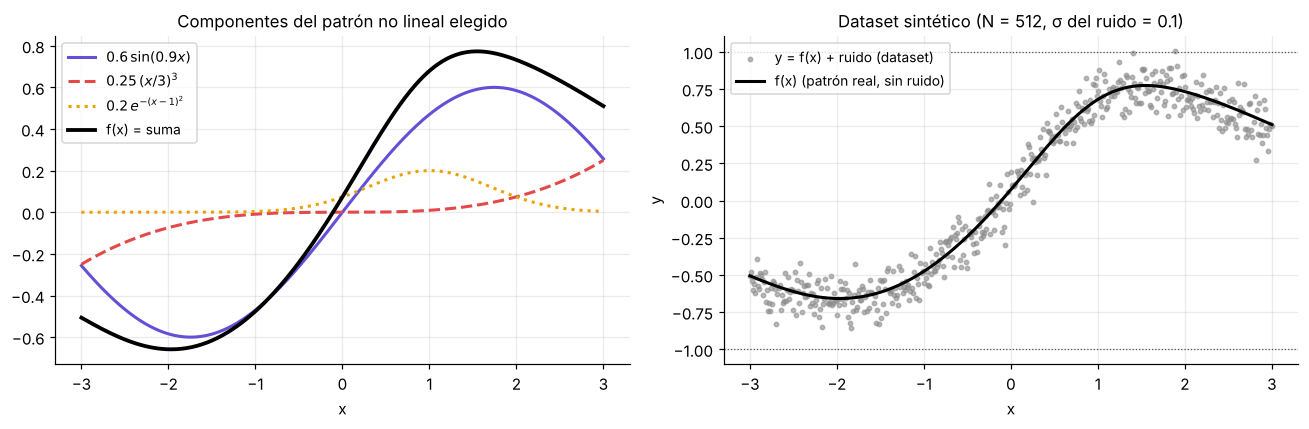

In [2]:
# Dataset sintético:  y = f(x) + ruido
N = 512                                  # n >= 200 (consigna); 512 = 16 x 32 -> mini-batches exactos
x = np.linspace(-3, 3, N)                # dominio simétrico

def f_true(x):
    """Patrón no lineal = trigonométrica + polinómica (grado 3) + exponencial (campana desplazada)."""
    return 0.6 * np.sin(0.9 * x) + 0.25 * (x / 3) ** 3 + 0.2 * np.exp(-(x - 1) ** 2)

SIGMA = 0.1                              # desvío estándar del ruido gaussiano
rng_data = np.random.default_rng(SEED_DATA)
ruido = rng_data.normal(0.0, SIGMA, size=N)
y = f_true(x) + ruido

print(f"N = {N} muestras, x en [{x.min():.0f}, {x.max():.0f}]")
print(f"f(x) en [{f_true(x).min():.3f}, {f_true(x).max():.3f}]  -> acotada dentro de [-1, 1]")
print(f"Ruido: media = {ruido.mean():+.4f}, desvío = {ruido.std():.4f}  -> MSE irreducible ~ {np.mean(ruido**2):.4f}")
print(f"Varianza de y = {y.var():.4f}  (costo de predecir siempre la media; sirve de escala para el R²)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(x, 0.6 * np.sin(0.9 * x), label=r"$0.6\,\sin(0.9x)$", color="#6250d6")
ax.plot(x, 0.25 * (x / 3) ** 3, label=r"$0.25\,(x/3)^3$", color="#e34948", ls="--")
ax.plot(x, 0.2 * np.exp(-(x - 1) ** 2), label=r"$0.2\,e^{-(x-1)^2}$", color="#eda100", ls=":")
ax.plot(x, f_true(x), label="f(x) = suma", color="k", lw=2.5)
ax.set_title("Componentes del patrón no lineal elegido"); ax.set_xlabel("x"); ax.legend()

ax = axes[1]
ax.scatter(x, y, s=8, color="0.55", alpha=0.6, label="y = f(x) + ruido (dataset)")
ax.plot(x, f_true(x), color="k", lw=2, label="f(x) (patrón real, sin ruido)")
ax.axhline(1, color="0.3", lw=0.8, ls=":"); ax.axhline(-1, color="0.3", lw=0.8, ls=":")
ax.set_title(f"Dataset sintético (N = {N}, σ del ruido = {SIGMA})"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()


### Modelo, costo y gradiente

Modelo: $\hat y = \tanh(wx + b)$. Costo: MSE. Derivando con regla de la cadena (como en clase), para cada muestra el "error imputado" a la neurona es

$$
\delta_i = \frac{2}{m}(\hat y_i - y_i)(1 - \hat y_i^{\,2})
$$

y con eso $\partial J/\partial w = \sum \delta_i x_i$ y $\partial J/\partial b = \sum \delta_i$.

El factor $(1-\hat y^2)$ es la derivada de la tanh y termina explicando casi todo lo que pasa en este TP. Cuando la tanh se satura (salida pegada a +1 o -1), ese factor da casi cero y el gradiente desaparece aunque el modelo se esté equivocando muchísimo.

Antes de usar el gradiente lo comparé con diferencias finitas en algunos puntos al azar. Si la derivada tuviera un error de signo, las curvas igual podrían "verse bien" y no me daría cuenta. Hice lo mismo con el Hessiano, que uso solo para analizar la superficie en 1d.

In [3]:
# Modelo, función de costo y gradiente analítico (regla de la cadena)
def forward(w, b, x):
    """Red de una sola conexión sináptica: y_hat = tanh(w x + b)."""
    return np.tanh(w * x + b)

def cost(w, b, x=x, y=y):
    """MSE: J(w,b) = (1/m) * sum (y_hat - y)^2."""
    return np.mean((forward(w, b, x) - y) ** 2)

def grad(w, b, x=x, y=y):
    """Gradiente analítico de J respecto de (w, b) sobre las muestras (x, y) recibidas.
    delta_i = dJ/dz_i = (2/m) (y_hat_i - y_i) (1 - y_hat_i^2)   -> 'error imputado' a la neurona
    dJ/dw = sum delta_i * x_i      dJ/db = sum delta_i
    """
    y_hat = forward(w, b, x)
    delta = (2.0 / x.size) * (y_hat - y) * (1.0 - y_hat ** 2)
    return np.sum(delta * x), np.sum(delta)

def hessian(w, b, x=x, y=y):
    """Hessiano analítico (segundas derivadas). Solo se usa para ANALIZAR la superficie
    (convexidad, curvatura en el mínimo), nunca para entrenar con GD/Adam."""
    t = forward(w, b, x)
    s = 1.0 - t ** 2
    h = (2.0 / x.size) * s * (s - 2.0 * t * (t - y))      # d2J/dz_i^2
    return np.array([[np.sum(h * x * x), np.sum(h * x)],
                     [np.sum(h * x),     np.sum(h)]])

# --- Verificación del gradiente: derivada analítica vs diferencias finitas centradas ---
rng_chk = np.random.default_rng(0)
filas = []
for w_c, b_c in rng_chk.uniform(-3, 3, size=(5, 2)):
    h = 1e-6
    num_w = (cost(w_c + h, b_c) - cost(w_c - h, b_c)) / (2 * h)
    num_b = (cost(w_c, b_c + h) - cost(w_c, b_c - h)) / (2 * h)
    an_w, an_b = grad(w_c, b_c)
    err = np.linalg.norm([an_w - num_w, an_b - num_b]) / max(1e-12, np.linalg.norm([an_w, an_b]) + np.linalg.norm([num_w, num_b]))
    filas.append({"w": w_c, "b": b_c, "dJ/dw analítica": an_w, "dJ/dw numérica": num_w,
                  "dJ/db analítica": an_b, "dJ/db numérica": num_b, "error relativo": err})
display(pd.DataFrame(filas).style.format("{:.3e}", subset=["error relativo"]).format("{:.6f}", subset=pd.IndexSlice[:, ["w", "b", "dJ/dw analítica", "dJ/dw numérica", "dJ/db analítica", "dJ/db numérica"]]))
print("Gradiente verificado:", all(r["error relativo"] < 1e-7 for r in filas))

# --- Misma verificación para el Hessiano (derivando numéricamente el gradiente analítico) ---
w_c, b_c, h = 0.7, -0.4, 1e-6
H_num = np.column_stack([(np.array(grad(w_c + h, b_c)) - np.array(grad(w_c - h, b_c))) / (2 * h),
                         (np.array(grad(w_c, b_c + h)) - np.array(grad(w_c, b_c - h))) / (2 * h)])
print(f"Hessiano verificado: error relativo = {np.linalg.norm(H_num - hessian(w_c, b_c)) / np.linalg.norm(H_num):.1e}")


,w,b,dJ/dw analítica,dJ/dw numérica,dJ/db analítica,dJ/db numérica,error relativo
0,0.821770,-1.381280,-0.517247,-0.517247,-0.497514,-0.497514,2.345e-11
1,-2.754159,-2.900834,-0.177613,-0.177613,0.117722,0.117722,3.176e-10
2,1.879621,2.476533,-0.182879,-0.182879,0.193837,0.193837,9.434e-11
3,0.639815,1.376979,-0.781114,-0.781114,0.568188,0.568188,1.683e-11
4,0.261750,2.610435,-0.144851,-0.144851,0.082462,0.082462,4.712e-10


Gradiente verificado: True
Hessiano verificado: error relativo = 4.2e-11


### Referencia: el mejor costo posible (J*)

Como el modelo tiene solo 2 parámetros, puedo darme el lujo de encontrar el mínimo global a fuerza bruta: evalúo J en una grilla de 481 x 321 puntos y refino el mejor con Newton. Esto no es un cuarto optimizador para comparar, es una regla para medir a los otros tres. En una red real no se podría hacer.

In [4]:
# Referencia: el MEJOR costo que este modelo puede alcanzar (J*)
# Búsqueda exhaustiva en grilla + refinamiento con Newton (2do orden).
# Sirve como "línea de llegada" para medir qué tan cerca termina cada optimizador.
def cost_grid(W, B, x=x, y=y):
    """J evaluada en una malla (W, B) de forma vectorizada (fila por fila para no saturar memoria)."""
    J = np.empty_like(W, dtype=float)
    for i in range(W.shape[0]):
        y_hat = np.tanh(W[i][:, None] * x[None, :] + B[i][:, None])
        J[i] = np.mean((y_hat - y[None, :]) ** 2, axis=1)
    return J

Wg, Bg = np.meshgrid(np.linspace(-6, 6, 481), np.linspace(-4, 4, 321))
Jg = cost_grid(Wg, Bg)
i_min = np.unravel_index(np.argmin(Jg), Jg.shape)
theta = np.array([Wg[i_min], Bg[i_min]])
for _ in range(20):                                   # Newton: converge cuadráticamente cerca del mínimo
    theta = theta - np.linalg.solve(hessian(*theta), np.array(grad(*theta)))
W_STAR, B_STAR = theta
J_STAR = cost(W_STAR, B_STAR)
H_STAR = hessian(W_STAR, B_STAR)
eig = np.linalg.eigvalsh(H_STAR)

y_star = forward(W_STAR, B_STAR, x)
sesgo_modelo = np.mean((y_star - f_true(x)) ** 2)     # lo que el modelo NO puede representar de f(x)
ruido_mse    = np.mean((y - f_true(x)) ** 2)          # lo que nadie puede predecir (ruido)
R2_STAR = 1 - J_STAR / y.var()

print(f"Mínimo global:  w* = {W_STAR:.4f},  b* = {B_STAR:.4f}")
print(f"J* = {J_STAR:.5f}   |grad J(w*,b*)| = {np.linalg.norm(grad(W_STAR, B_STAR)):.1e}   R²* = {R2_STAR:.4f}")
print(f"Autovalores del Hessiano en el mínimo: {eig[0]:.4f}, {eig[1]:.4f}  -> ambos > 0 (mínimo genuino)")
print(f"Número de condición kappa = {eig[1] / eig[0]:.2f}  -> cerca del mínimo el 'cuenco' es casi redondo:"
      f" la dificultad de este problema NO está en el mínimo sino lejos de él (ver 1d)")
print(f"Descomposición aproximada de J*: error de modelo (sesgo) = {sesgo_modelo:.4f} + ruido = {ruido_mse:.4f}  (suma = {sesgo_modelo + ruido_mse:.4f})")
from numpy.lib.stride_tricks import sliding_window_view
vecinos = sliding_window_view(Jg, (3, 3))
mascara = np.ones((3, 3), bool); mascara[1, 1] = False
min_vecinos = np.where(mascara, vecinos, np.inf).min(axis=(2, 3))
n_min_locales = int(np.sum(Jg[1:-1, 1:-1] < min_vecinos))
print(f"Mínimos locales interiores encontrados en la grilla (w en [-6,6], b en [-4,4]): {n_min_locales}")


Mínimo global:  w* = 0.4466,  b* = 0.0801
J* = 0.03431   |grad J(w*,b*)| = 9.8e-18   R²* = 0.8972
Autovalores del Hessiano en el mínimo: 0.8284, 1.1379  -> ambos > 0 (mínimo genuino)
Número de condición kappa = 1.37  -> cerca del mínimo el 'cuenco' es casi redondo: la dificultad de este problema NO está en el mínimo sino lejos de él (ver 1d)
Descomposición aproximada de J*: error de modelo (sesgo) = 0.0238 + ruido = 0.0089  (suma = 0.0327)
Mínimos locales interiores encontrados en la grilla (w en [-6,6], b en [-4,4]): 1


El mejor ajuste posible es $\tanh(0.447x + 0.080)$, con J* = 0.0343 y R² = 0.897. Ningún optimizador puede bajar de ahí, así que en lo que sigue "converger" quiere decir llegar a 0.0343.

De ese error, aproximadamente 0.024 viene de que una neurona no puede dibujar los tramos que suben y bajan, y 0.009 es el ruido. O sea que cerca del 70% del error final es limitación del modelo.

Dos cosas más que me sirvieron después. En la grilla hay un único mínimo, así que si un optimizador no llega no es porque cayó en un mínimo local. Y alrededor del mínimo el "pozo" es casi redondo (autovalores 0.83 y 1.14). La dificultad, entonces, no está cerca del mínimo sino lejos, como se ve en 1d.

### 1a) Implementación del Gradiente Descendente (1 punto)
- Implementar el algoritmo del Gradiente Descendente (GD) para minimizar \\( J(w, b) \\).
- Utilizar 100 épocas y 3 diferentes learning rates `(0.1, 0.01, 0.001)`.
- Inicializar valores de \\( w \\) y \\( b \\) de manera aleatoria con `np.random.randn()`.
- Graficar la función de Costo \\( J(w, b) \\) VS número de época para comparar cómo converge la función para cada uno de los 3 learning rates. Las 3 gráficas deben estar en el mismo plot y superpuestas para que la comparación visual sea más fácil. Deben graficarlas con diferente color y con leyenda para no confundirlas.

<br>

El optimizador del Gradiente Descendente se debe implementar haciendo el código desde cero y paso a paso. Se pueden usar librerías como `numpy`, `scipy`, `matplotlib` o similares. Pero no está permitido usar PyTorch ni TensorFlow o frameworks que ya contengan el optimizador desarrollado.

#### Resolución 1a)

GD clásico: en cada época calculo el gradiente con las 512 muestras y doy un paso de tamaño lr por el gradiente, en sentido contrario. El paso es proporcional a la pendiente. Eso está bien cerca del mínimo (frena solo), pero en una zona plana casi no se mueve.

Sobre la inicialización: uso `np.random.randn()` con semilla 35, y esos mismos valores los reutilizo en 1b. Elegí la semilla a propósito. Primero probé con la 42, pero arranca en (0.50, -0.14), prácticamente encima del óptimo, y los tres optimizadores llegaban igual; no había nada para comparar. La 35 da (-1.89, -0.41): un modelo "dado vuelta" (con w negativo la curva baja donde los datos suben) y saturado. Es un arranque difícil, pero no raro: casi la mitad de las inicializaciones con randn tienen w negativo. Para no depender de esta elección, en 1c repito todo con 500 semillas.

In [5]:
# 1a) Gradiente Descendente (full-batch) implementado desde cero
# Inicialización aleatoria con np.random.randn() (se guarda y se reutiliza en TODOS los optimizadores)
np.random.seed(SEED_INIT)
W0 = np.random.randn()
B0 = np.random.randn()
print(f"Punto inicial común: w0 = {W0:.4f}, b0 = {B0:.4f}  ->  J(w0, b0) = {cost(W0, B0):.4f}"
      f"  |grad J| = {np.linalg.norm(grad(W0, B0)):.4f}")

def train_gd(w0, b0, lr, epochs=EPOCHS):
    """GD clásico: 1 actualización por época usando el gradiente de TODO el dataset.
    Devuelve el historial por época (época 0 = punto inicial, sin entrenar)."""
    w, b = float(w0), float(b0)
    hist = {"J": [cost(w, b)], "w": [w], "b": [b]}
    diag = []                              # (|gradiente|, |paso|) en cada actualización, para el análisis de 1d
    for epoch in range(epochs):
        dJ_dw, dJ_db = grad(w, b)          # 1) gradiente con las N muestras
        w = w - lr * dJ_dw                 # 2) paso en dirección opuesta al gradiente
        b = b - lr * dJ_db
        hist["J"].append(cost(w, b)); hist["w"].append(w); hist["b"].append(b)
        diag.append((np.hypot(dJ_dw, dJ_db), lr * np.hypot(dJ_dw, dJ_db)))
    out = {k: np.array(v) for k, v in hist.items()}
    out["diag"] = np.array(diag)
    out["path_w"], out["path_b"] = out["w"], out["b"]   # en GD la trayectoria por paso = por época
    out["updates"] = epochs
    return out

results = {opt: {} for opt in OPTS}
times = {opt: {} for opt in OPTS}
for lr in LRS:
    t0 = time.perf_counter()
    results["GD"][lr] = train_gd(W0, B0, lr)
    times["GD"][lr] = (time.perf_counter() - t0) * 1e3
    r = results["GD"][lr]
    print(f"GD  lr={lr:<6}  J(época 100) = {r['J'][-1]:.5f}   (w, b) final = ({r['w'][-1]:+.3f}, {r['b'][-1]:+.3f})")


Punto inicial común: w0 = -1.8897, b0 = -0.4136  ->  J(w0, b0) = 2.1842  |grad J| = 0.1464
GD  lr=0.1     J(época 100) = 0.03432   (w, b) final = (+0.446, +0.078)
GD  lr=0.01    J(época 100) = 2.15794   (w, b) final = (-1.730, -0.440)
GD  lr=0.001   J(época 100) = 2.18205   (w, b) final = (-1.875, -0.416)


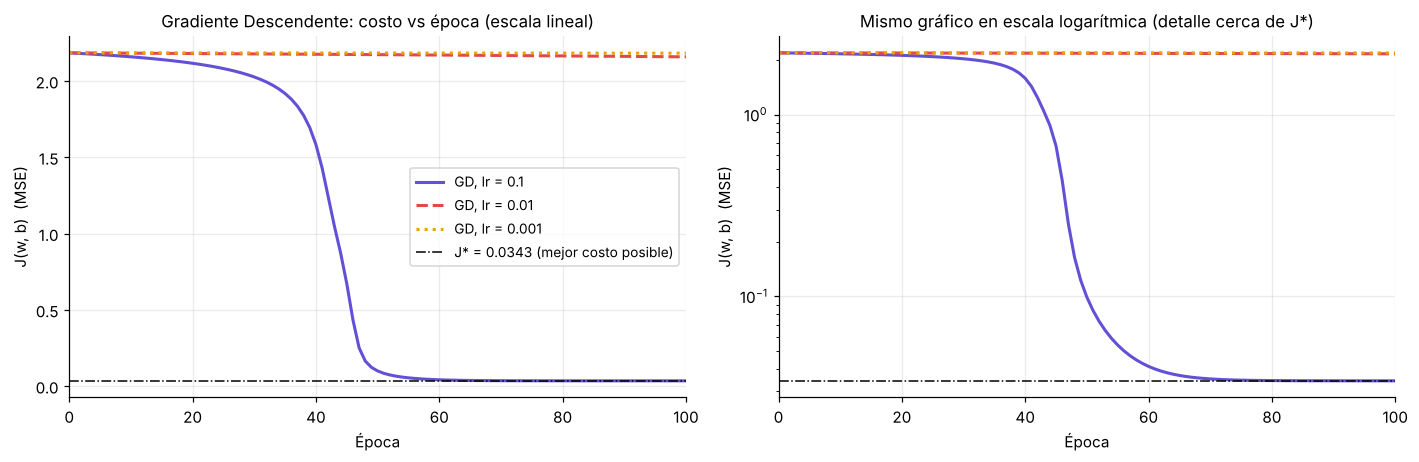

In [6]:
# --- Gráfico pedido: J vs época, los 3 learning rates superpuestos ---
ep = np.arange(EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, escala in zip(axes, ["linear", "log"]):
    for lr in LRS:
        ax.plot(ep, results["GD"][lr]["J"], color=COLOR_LR[lr], ls=LS_LR[lr], label=f"GD, lr = {lr}")
    ax.axhline(J_STAR, color="k", lw=1, ls="-.", label=f"J* = {J_STAR:.4f} (mejor costo posible)")
    ax.set_yscale(escala); ax.set_xlabel("Época"); ax.set_ylabel("J(w, b)  (MSE)")
    ax.set_xlim(0, EPOCHS)
axes[0].set_title("Gradiente Descendente: costo vs época (escala lineal)")
axes[1].set_title("Mismo gráfico en escala logarítmica (detalle cerca de J*)")
axes[0].legend(loc="center right")
plt.tight_layout(); plt.show()


Con lr = 0.1 es el único caso que converge, y la curva tiene forma de escalón. Durante unas 40 épocas casi no baja (de 2.18 a 1.58), entre la 40 y la 50 cae casi todo y desde la época 64 queda pegado a J*. Termina en 0.03432, que es J*. En ningún momento el costo sube.

El escalón se explica con el gradiente. Al principio la norma vale 0.146 porque la tanh está saturada, así que cada paso mueve los parámetros apenas 0.015. Cuando w se acerca a 0, el modelo sale de la saturación, el gradiente crece hasta cerca de 1.5 y ahí se acelera. El cruce de w = 0 (cuando la curva "se da vuelta") pasa en la época 45, justo en medio de la caída.

Con 0.01 y 0.001 hace el mismo camino, pero 10 y 100 veces más lento. Con 0.01, en 100 épocas llega a donde lr = 0.1 llegaba en 10 (J = 2.158). No está atrapado en un mínimo: le falta pendiente. Calculo que necesitaría unas 500 épocas.

### 1b) Implementación de Adam (2 punto)  
- Implementar el algoritmo de Adam para minimizar \\( J(w, b) \\).  
- Utilizar 100 épocas y 3 diferentes learning rates `(0.1, 0.01, 0.001)`.
- Utilizar los mismos valores de \\( w \\) y \\( b \\) que se usaron para GD **(IMPORTANTE)**.
- Hacer 2 modelos, uno full-batch y otro con mini-batch.
- El batch size es a elección de ustedes, pero debe ser mayor o igual a 16.
- Graficar la función de Costo \\( J(w, b) \\) VS número de época para comparar cómo converge la función para ambos modelos y para los 3 learning rates. Deben haber 2 plots separados o 2 subplots, uno para las 3 gráficas de Adam full-batch y otro para las 3 gráficas de Adam mini-batch.

<br>

Al igual que para GD, ambas versiones del optimizador Adam también se deben implementar desde cero y paso a paso. Se pueden usar librerías como `numpy`, `scipy`, `matplotlib` o similares. Pero no está permitido usar PyTorch ni TensorFlow o frameworks que ya contengan el optimizador desarrollado.

#### Resolución 1b)

Implementé Adam siguiendo el algoritmo 1 del paper (Kingma & Ba, 2015, https://arxiv.org/abs/1412.6980), con los valores por defecto β1 = 0.9, β2 = 0.999 y ε = 1e-8. La actualización es

$$
\theta_t = \theta_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}
$$

donde m es un promedio móvil del gradiente (inercia, memoria de unas 10 actualizaciones) y v uno del gradiente al cuadrado (escala, memoria de unas 1000). Lo que más me sirvió para entender los resultados es que el cociente m/√v queda cerca de ±1 cuando el gradiente es consistente. Por eso Adam da pasos de tamaño parecido al lr, sea el gradiente grande o chico. GD, en cambio, da pasos de lr por gradiente.

Hice una sola función para los dos modelos. Full-batch usa las 512 muestras por paso, o sea 1 actualización por época. Mini-batch usa lotes de 32 (cumple el mínimo de 16 y es potencia de 2), o sea 16 actualizaciones por época. Algunas decisiones:

- Mezclo los datos al empezar cada época y recorro sin reemplazo, así cada muestra se usa una vez por época.
- El contador t es global, no se reinicia por época; si se reiniciara, la corrección de sesgo volvería a inflar los pasos al arrancar cada época.
- El costo de cada época lo mido sobre el dataset completo, no como promedio de los lotes. Así es comparable con GD.
- Los dos parten de los mismos w0 y b0 de 1a.

In [7]:
# 1b) Adam implementado desde cero: full-batch y mini-batch con la MISMA función
def train_adam(w0, b0, lr, epochs=EPOCHS, batch_size=None, seed=SEED_BATCH,
               beta1=BETA1, beta2=BETA2, eps=EPS):
    """Adam. batch_size=None -> full-batch (1 actualización/época).
    batch_size=k -> mini-batch: en cada época se baraja el dataset y se recorre en bloques de k
    muestras (N/k actualizaciones/época). El costo por época se mide SIEMPRE sobre el dataset
    completo, para que la curva sea comparable con GD y con Adam full-batch."""
    n = x.size
    bs = n if batch_size is None else batch_size
    rng = np.random.default_rng(seed)
    w, b = float(w0), float(b0)
    m_w = m_b = 0.0        # 1er momento: promedio móvil del gradiente ("inercia" / dirección)
    v_w = v_b = 0.0        # 2do momento: promedio móvil del gradiente al cuadrado ("escala")
    t = 0                  # contador GLOBAL de actualizaciones (no se reinicia por época)
    hist = {"J": [cost(w, b)], "w": [w], "b": [b]}
    path_w, path_b = [w], [b]                     # trayectoria actualización por actualización
    diag = []                                     # (|gradiente|, |paso|, sqrt(v_hat) de w) por actualización -> análisis de 1d
    for epoch in range(epochs):
        idx = rng.permutation(n) if bs < n else np.arange(n)   # barajado por época (sin reemplazo)
        for start in range(0, n, bs):
            batch = idx[start:start + bs]
            g_w, g_b = grad(w, b, x[batch], y[batch])           # gradiente del (mini-)batch
            t += 1
            m_w = beta1 * m_w + (1 - beta1) * g_w
            m_b = beta1 * m_b + (1 - beta1) * g_b
            v_w = beta2 * v_w + (1 - beta2) * g_w ** 2
            v_b = beta2 * v_b + (1 - beta2) * g_b ** 2
            m_w_hat, m_b_hat = m_w / (1 - beta1 ** t), m_b / (1 - beta1 ** t)   # corrección de sesgo
            v_w_hat, v_b_hat = v_w / (1 - beta2 ** t), v_b / (1 - beta2 ** t)
            paso_w = lr * m_w_hat / (np.sqrt(v_w_hat) + eps)   # paso adaptativo de cada parámetro
            paso_b = lr * m_b_hat / (np.sqrt(v_b_hat) + eps)
            w, b = w - paso_w, b - paso_b
            path_w.append(w); path_b.append(b)
            diag.append((np.hypot(g_w, g_b), np.hypot(paso_w, paso_b), np.sqrt(v_w_hat)))
        hist["J"].append(cost(w, b)); hist["w"].append(w); hist["b"].append(b)
    out = {k: np.array(v) for k, v in hist.items()}
    out["path_w"], out["path_b"], out["updates"], out["diag"] = np.array(path_w), np.array(path_b), t, np.array(diag)
    return out

for lr in LRS:
    for opt, bs in [("Adam full-batch", None), ("Adam mini-batch", BATCH_SIZE)]:
        t0 = time.perf_counter()
        results[opt][lr] = train_adam(W0, B0, lr, batch_size=bs)
        times[opt][lr] = (time.perf_counter() - t0) * 1e3
        r = results[opt][lr]
        print(f"{opt:<16} lr={lr:<6} J(época 100) = {r['J'][-1]:.5f}  (w, b) final = ({r['w'][-1]:+.3f}, {r['b'][-1]:+.3f})"
              f"  actualizaciones = {r['updates']}")


Adam full-batch  lr=0.1    J(época 100) = 0.11280  (w, b) final = (+1.496, +0.204)  actualizaciones = 100
Adam mini-batch  lr=0.1    J(época 100) = 0.03452  (w, b) final = (+0.432, +0.064)  actualizaciones = 1600
Adam full-batch  lr=0.01   J(época 100) = 1.35955  (w, b) final = (-0.593, -1.742)  actualizaciones = 100
Adam mini-batch  lr=0.01   J(época 100) = 0.03432  (w, b) final = (+0.448, +0.083)  actualizaciones = 1600
Adam full-batch  lr=0.001  J(época 100) = 2.16493  (w, b) final = (-1.787, -0.523)  actualizaciones = 100
Adam mini-batch  lr=0.001  J(época 100) = 0.33390  (w, b) final = (+0.162, -0.439)  actualizaciones = 1600


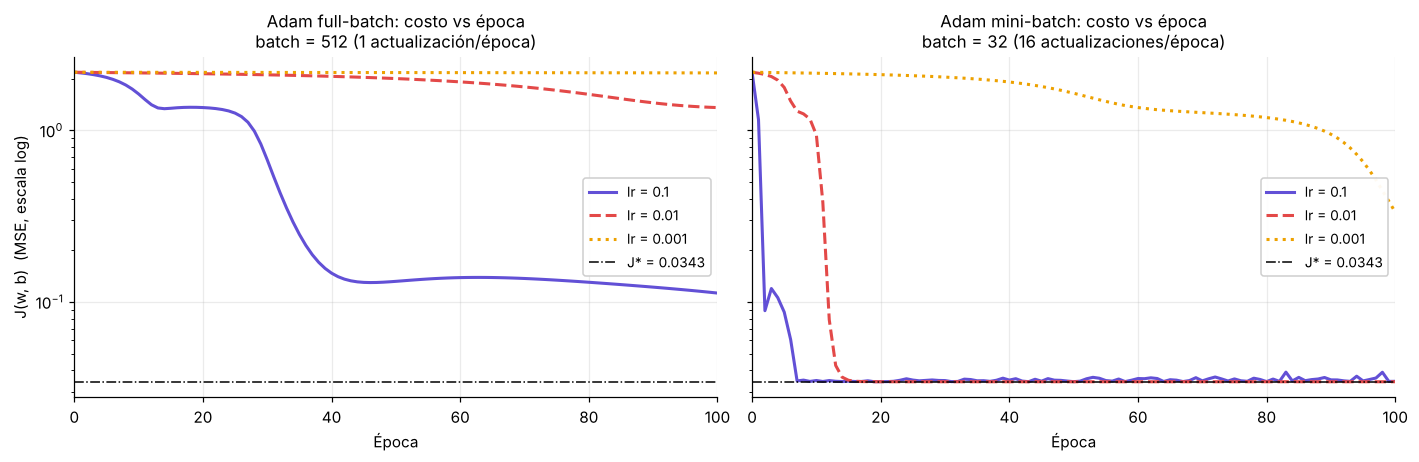

In [8]:
# --- Gráfico pedido: 2 subplots (Adam full-batch | Adam mini-batch), 3 learning rates cada uno ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, opt in zip(axes, ["Adam full-batch", "Adam mini-batch"]):
    for lr in LRS:
        ax.plot(ep, results[opt][lr]["J"], color=COLOR_LR[lr], ls=LS_LR[lr], label=f"lr = {lr}")
    ax.axhline(J_STAR, color="k", lw=1, ls="-.", label=f"J* = {J_STAR:.4f}")
    ax.set_yscale("log"); ax.set_xlim(0, EPOCHS); ax.set_xlabel("Época")
    extra = f"batch = {N} (1 actualización/época)" if opt == "Adam full-batch" else f"batch = {BATCH_SIZE} ({N // BATCH_SIZE} actualizaciones/época)"
    ax.set_title(f"{opt}: costo vs época\n{extra}")
    ax.legend(loc="center right", framealpha=0.95)
axes[0].set_ylabel("J(w, b)  (MSE, escala log)")
plt.tight_layout(); plt.show()


Full-batch con lr = 0.1 arranca mucho más rápido que GD (en la época 13 ya está en 1.35, GD seguía en 2.15), se queda un rato en una meseta, vuelve a bajar y después se estanca cerca de 0.13. Termina en 0.113, más de tres veces J*, en (1.50, 0.20), lejos del óptimo (0.45, 0.08). Al principio pensé que era lentitud, pero en realidad se pasó del mínimo. Lo analizo en 1d. Con 0.01 baja a ritmo constante hasta 1.36 y con 0.001 casi no se mueve.

Mini-batch con lr = 0.1 es lo más rápido de todo el TP: en la época 2 ya hizo el 90% de la bajada. Pero no se queda quieto: oscila alrededor de 0.035 y en 47 de las 100 épocas el costo sube respecto de la anterior. Con 0.01 queda el mejor resultado: llega en 12-14 épocas y termina en J* sin oscilación visible. Con 0.001 todavía está bajando en la época 100 (0.334).

Hay una cuenta simple que explica casi todo el cuadro. Si Adam avanza más o menos lr por paso, para que w vaya de -1.89 a 0.45 (2.34 de distancia) hacen falta del orden de 2.34/lr pasos: 23 con 0.1, 234 con 0.01 y 2340 con 0.001. Full-batch tiene 100 pasos y mini-batch 1600. Con eso se ve quién puede llegar y quién no. Es condición necesaria, no suficiente: full-batch con 0.1 tiene pasos de sobra y aun así termina lejos.

### 1c) Comparativa de optimizadores (0.5 puntos)  
- Comparar el resultado y rendimiento de GD VS Adam (full-batch) VS Adam (mini-batch) para cada uno de los learning rates por separado. Hacerlo con gráficas y tablas. Deben haber 3 plots o 3 subplots, uno para cada learning rate. Y las leyendas deben diferenciar al optimizador por color.
- Graficar el dataset original sintético (y(x)) y compararlo con la función hallada por el modelo, para ver si efectivamente el modelo logró deducir un patrón no lineal parecido al patrón no lineal escogido para el dataset. Hacerlo para cada optimizador y cada learning rate en un plot grande de 9 subplots.
- Redactar conclusiones analíticas que resalten las diferencias entre cada optimizador. No solo deben comparar el resultado final del costo, sino también la velocidad de convergencia y otros aspectos que consideren relevantes. Le voy a tomar mucha importancia a este último punto, así que su análisis debe ser claro, detallado y con criterio acorde a los resultados obtenidos.

#### Resolución 1c)

Comparo por learning rate, primero contando épocas y después contando actualizaciones, porque mini-batch da 16 pasos por época y me parecía injusto mirar solo épocas. También repito todo con 500 inicializaciones para ver qué cosas se sostienen.

En la tabla: "brecha vs J*" es cuánto quedó por encima del mínimo posible. "Época 90%" es cuándo logró el 90% de la bajada posible. "Época estable" es desde cuándo J ya no vuelve a salir del 10% sobre J* (así penalizo llegar y después irse). "Épocas con J en subida" cuenta oscilación o ruido. R² negativo significa peor que predecir siempre la media.

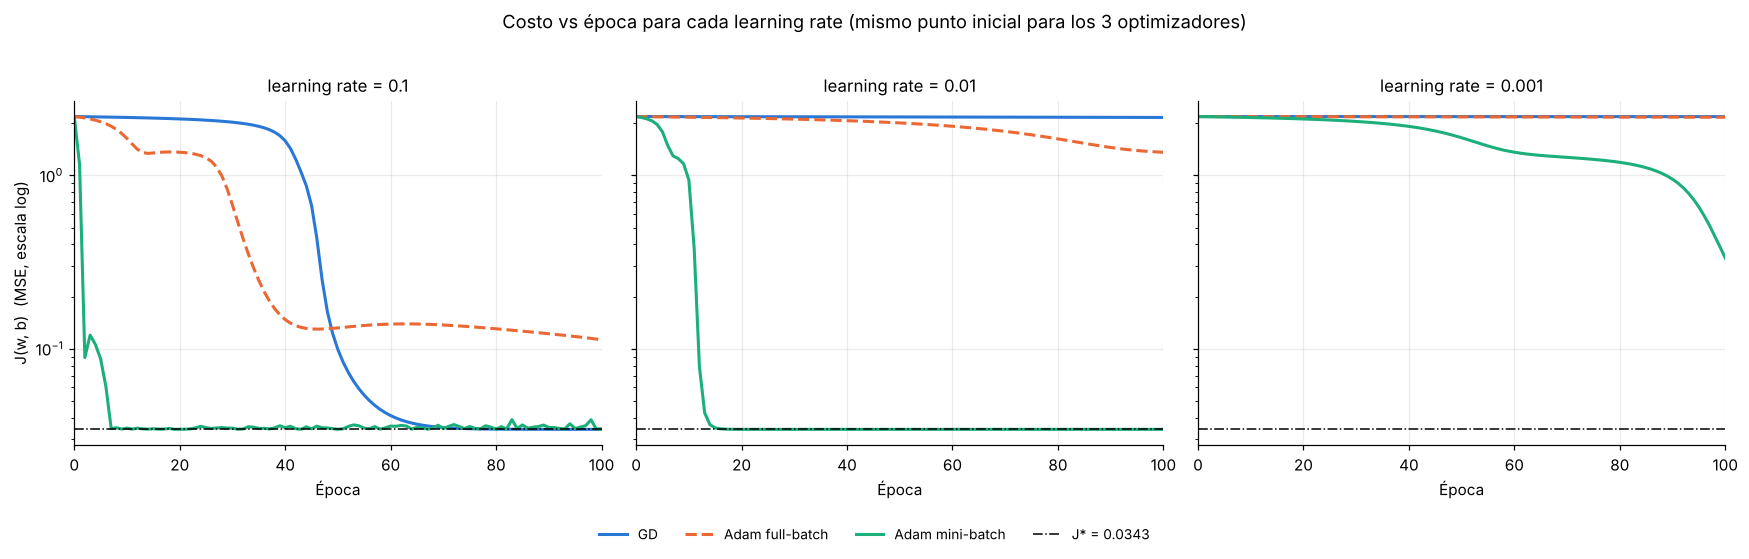

In [9]:
# 1c) Comparativa por learning rate: GD vs Adam full-batch vs Adam mini-batch
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, lr in zip(axes, LRS):
    for opt in OPTS:
        ax.plot(ep, results[opt][lr]["J"], color=COLOR_OPT[opt], ls=LS_OPT[opt], label=opt)
    ax.axhline(J_STAR, color="k", lw=1, ls="-.", label=f"J* = {J_STAR:.4f}")
    ax.set_yscale("log"); ax.set_xlim(0, EPOCHS)
    ax.set_title(f"learning rate = {lr}"); ax.set_xlabel("Época")
axes[0].set_ylabel("J(w, b)  (MSE, escala log)")
fig.suptitle("Costo vs época para cada learning rate (mismo punto inicial para los 3 optimizadores)", y=1.02)
plt.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.show()


In [10]:
# --- Tabla de métricas: resultado final, velocidad y estabilidad ---
def epoca_90(J):
    """Primera época en la que se logró el 90% de la reducción posible (de J0 hasta J*)."""
    umbral = J_STAR + 0.10 * (J[0] - J_STAR)
    k = np.flatnonzero(J <= umbral)
    return int(k[0]) if k.size else np.nan

def epoca_estable(J, tol=1.10):
    """Primera época a partir de la cual J queda SIEMPRE dentro de +10% de J* (llegó y no se fue)."""
    fuera = np.flatnonzero(J > tol * J_STAR)
    if fuera.size == 0: return 0
    return int(fuera[-1] + 1) if fuera[-1] + 1 < J.size else np.nan

filas = []
for lr in LRS:
    for opt in OPTS:
        r = results[opt][lr]; J = r["J"]
        filas.append({
            "lr": str(lr), "optimizador": opt,
            "J final": J[-1],
            "brecha vs J* (%)": 100 * (J[-1] / J_STAR - 1),
            "R² final": 1 - J[-1] / y.var(),
            "época 90% reducción": epoca_90(J),
            "época estable (J ≤ 1.1·J*)": epoca_estable(J),
            "épocas con J en subida": int(np.sum(np.diff(J) > 1e-12)),
            "actualizaciones": r["updates"],
            "w final": r["w"][-1], "b final": r["b"][-1],
            "dist. a (w*, b*)": np.hypot(r["w"][-1] - W_STAR, r["b"][-1] - B_STAR),
            "tiempo (ms)": times[opt][lr],
        })
tabla = pd.DataFrame(filas).set_index(["lr", "optimizador"])
fmt = {"J final": "{:.5f}", "brecha vs J* (%)": "{:.1f}", "R² final": lambda v: f"{round(v, 3) + 0.0:.3f}",
       "época 90% reducción": lambda v: "no alcanza" if np.isnan(v) else f"{int(v)}",
       "época estable (J ≤ 1.1·J*)": lambda v: "no alcanza" if np.isnan(v) else f"{int(v)}",
       "w final": "{:+.3f}", "b final": "{:+.3f}", "dist. a (w*, b*)": "{:.3f}", "tiempo (ms)": "{:.1f}"}
print(f"Referencia: J* = {J_STAR:.5f}, (w*, b*) = ({W_STAR:.3f}, {B_STAR:.3f}), R²* = {R2_STAR:.3f}. "
      f"Punto inicial: (w0, b0) = ({W0:.3f}, {B0:.3f}), J0 = {cost(W0, B0):.4f}")
display(tabla.style.format(fmt))


Referencia: J* = 0.03431, (w*, b*) = (0.447, 0.080), R²* = 0.897. Punto inicial: (w0, b0) = (-1.890, -0.414), J0 = 2.1842


En los 9 gráficos agregué, además de los datos y de la curva real, la mejor tanh posible (punteada). La distancia entre la curva de color y la punteada es error del optimizador; la distancia entre la punteada y la negra es error del modelo.

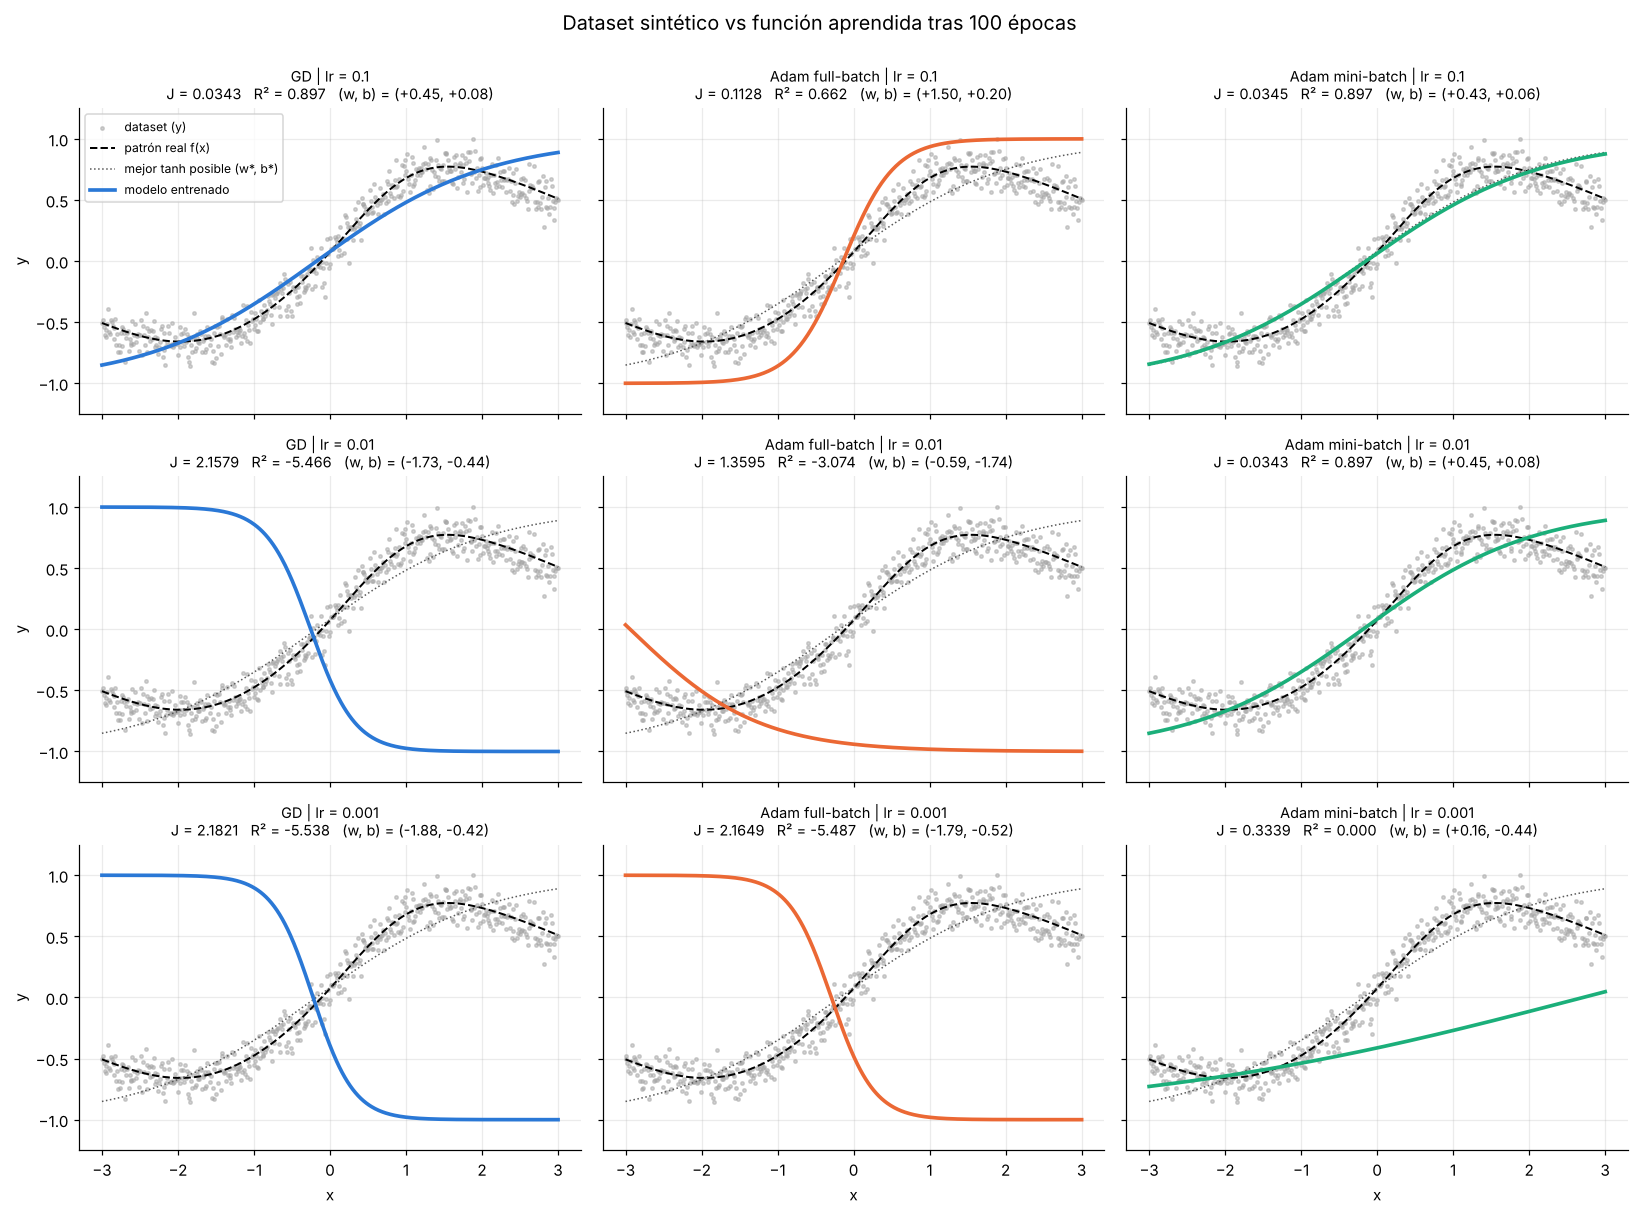

In [11]:
# --- 9 subplots: dataset vs función hallada, para cada optimizador (columnas) y learning rate (filas) ---
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=True, sharey=True)
for i, lr in enumerate(LRS):
    for j, opt in enumerate(OPTS):
        ax = axes[i, j]; r = results[opt][lr]
        ax.scatter(x, y, s=5, color="0.65", alpha=0.5, label="dataset (y)")
        ax.plot(x, f_true(x), color="k", lw=1.3, ls="--", label="patrón real f(x)")
        ax.plot(x, y_star, color="0.35", lw=1, ls=":", label="mejor tanh posible (w*, b*)")
        ax.plot(x, forward(r["w"][-1], r["b"][-1], x), color=COLOR_OPT[opt], lw=2.4, label="modelo entrenado")
        R2 = round(1 - r["J"][-1] / y.var(), 3) + 0.0   # (+0.0 evita imprimir "-0.000")
        ax.set_title(f"{opt} | lr = {lr}\nJ = {r['J'][-1]:.4f}   R² = {R2:.3f}   (w, b) = ({r['w'][-1]:+.2f}, {r['b'][-1]:+.2f})", fontsize=9.5)
        ax.set_ylim(-1.25, 1.25)
        if i == 2: ax.set_xlabel("x")
        if j == 0: ax.set_ylabel("y")
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Dataset sintético vs función aprendida tras 100 épocas", fontsize=13, y=1.0)
plt.tight_layout(); plt.show()


Por época, los tres procesan las mismas 512 muestras, pero mini-batch actualiza 16 veces y los otros una. Quería saber si mini-batch gana porque da mejores pasos o solamente porque da más, así que grafiqué el costo contra la cantidad de actualizaciones.

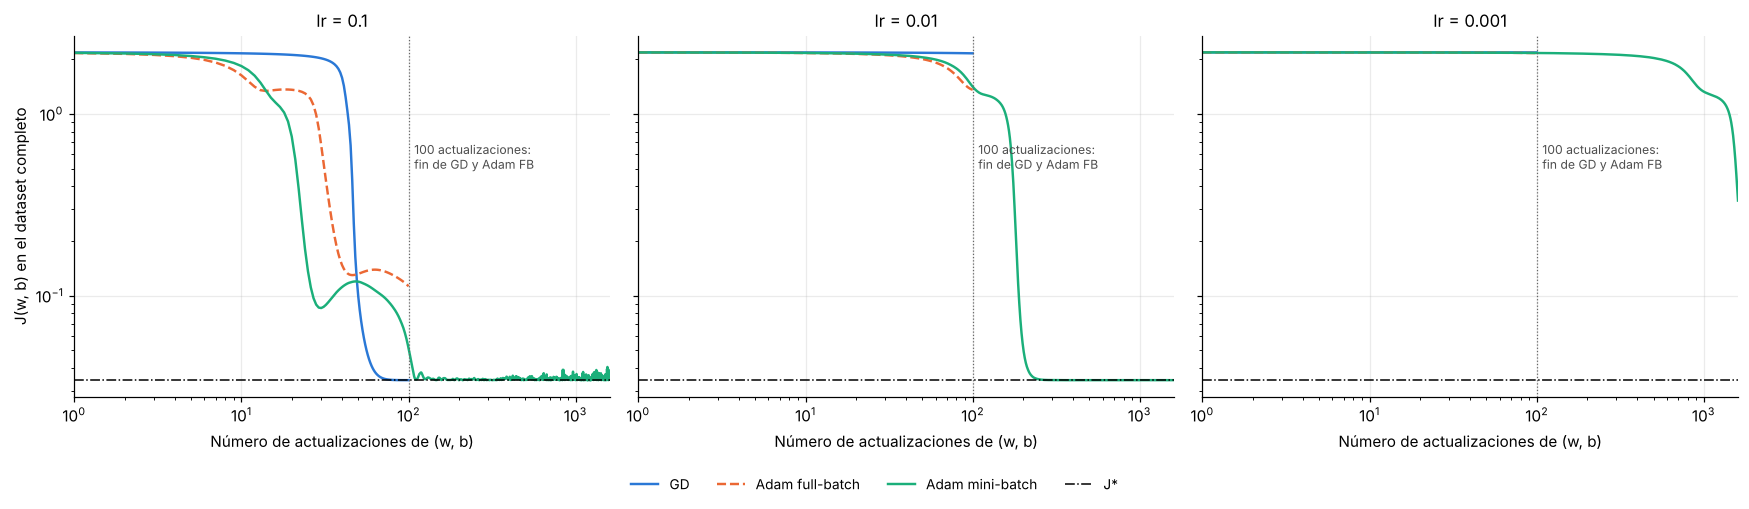

lr=0.1    tras 100 actualizaciones:  GD = 0.0343 | Adam FB = 0.1128 | Adam MB = 0.0513 (solo ~6 épocas)
lr=0.01   tras 100 actualizaciones:  GD = 2.1579 | Adam FB = 1.3595 | Adam MB = 1.4139 (solo ~6 épocas)
lr=0.001  tras 100 actualizaciones:  GD = 2.1821 | Adam FB = 2.1649 | Adam MB = 2.1677 (solo ~6 épocas)


In [12]:
# --- Mirada complementaria: costo vs NÚMERO DE ACTUALIZACIONES (no vs épocas) ---
# Por época, los 3 procesan las mismas N = 512 muestras (mismo cómputo de gradientes),
# pero mini-batch actualiza 16 veces y los otros 2 solo una. ¿Gana por "dar más pasos" o por "dar mejores pasos"?
def costo_por_actualizacion(r):
    return np.array([cost(w_, b_) for w_, b_ in zip(r["path_w"], r["path_b"])])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, lr in zip(axes, LRS):
    for opt in OPTS:
        Jk = costo_por_actualizacion(results[opt][lr])
        ax.plot(np.arange(1, Jk.size), Jk[1:], color=COLOR_OPT[opt], ls=LS_OPT[opt], label=opt, lw=1.6)
    ax.axhline(J_STAR, color="k", lw=1, ls="-.", label="J*")
    ax.axvline(EPOCHS, color="0.4", lw=0.8, ls=":")
    ax.text(EPOCHS * 1.08, 0.5, "100 actualizaciones:\nfin de GD y Adam FB", fontsize=8, color="0.3")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1, N // BATCH_SIZE * EPOCHS)
    ax.set_title(f"lr = {lr}"); ax.set_xlabel("Número de actualizaciones de (w, b)")
axes[0].set_ylabel("J(w, b) en el dataset completo")
plt.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.show()

for lr in LRS:
    Jmb = costo_por_actualizacion(results["Adam mini-batch"][lr])[:EPOCHS + 1]
    print(f"lr={lr:<6} tras 100 actualizaciones:  GD = {results['GD'][lr]['J'][-1]:.4f} | "
          f"Adam FB = {results['Adam full-batch'][lr]['J'][-1]:.4f} | Adam MB = {Jmb[-1]:.4f} (solo ~6 épocas)")


Para ver si lo de la semilla 35 se generaliza, repetí los 9 experimentos con 500 inicializaciones (seed s + randn, igual que en 1a, con s de 0 a 499). Cada corrida de mini-batch tiene además su propio mezclado. Para que tarde segundos y no minutos, vectoricé los mismos algoritmos y antes de usarlos chequeé que dieran exactamente lo mismo que las versiones paso a paso.

lr=0.1    diferencia máxima vectorizado vs paso a paso (GD, Adam FB, Adam MB): 0.0e+00


lr=0.01   diferencia máxima vectorizado vs paso a paso (GD, Adam FB, Adam MB): 0.0e+00
lr=0.001  diferencia máxima vectorizado vs paso a paso (GD, Adam FB, Adam MB): 0.0e+00

Inicializaciones: 48% arrancan con w0 < 0 (curva invertida) | 45% arrancan con J0 > 1 | la semilla 35 tiene J0 = 2.184 (percentil 99%)


4500 entrenamientos completados en 6.0 s


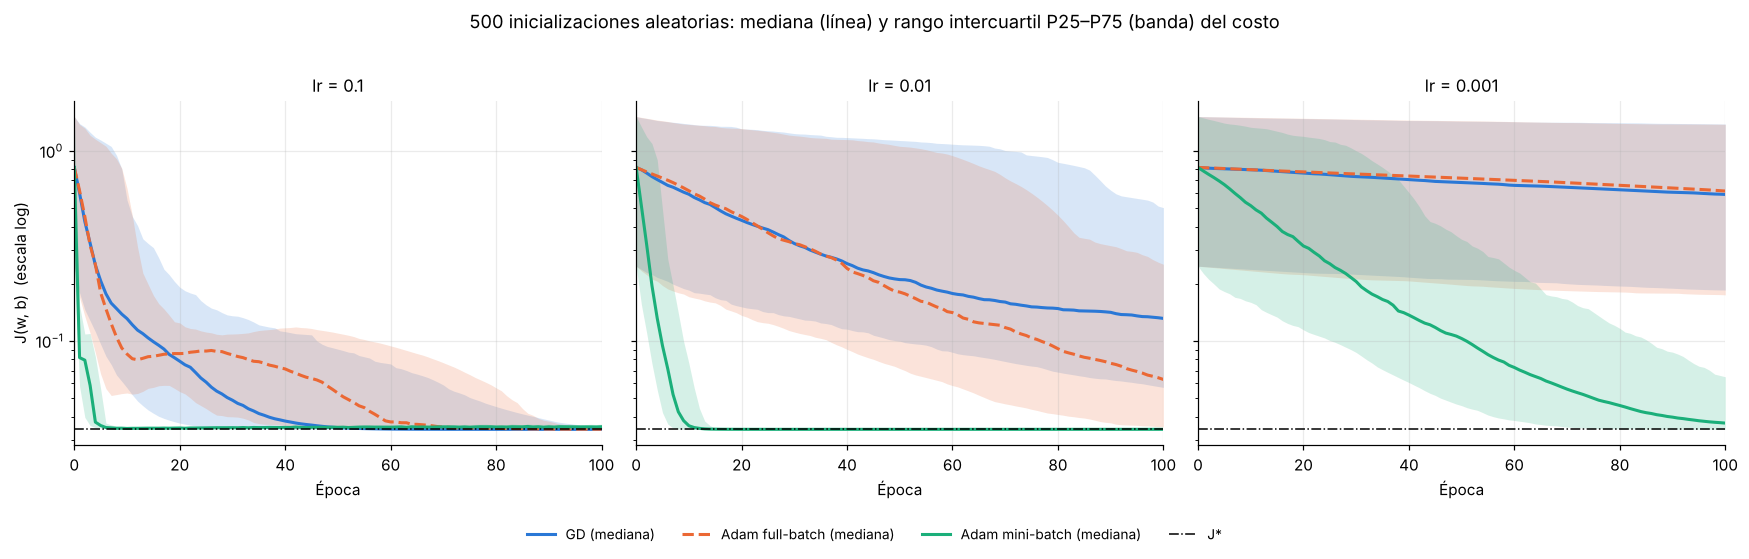

In [13]:
# Robustez: ¿las conclusiones dependen del punto inicial? -> 500 inicializaciones np.random.randn()
# Versión vectorizada de los mismos algoritmos (entrena las 500 corridas en paralelo).
def train_vec(w0s, b0s, lr, metodo, batch_size=None, batch_seeds=None, epochs=EPOCHS):
    """metodo: 'gd' o 'adam'. Misma matemática que train_gd / train_adam, aplicada a S corridas a la vez."""
    w = np.array(w0s, float); b = np.array(b0s, float); S = w.size; n = x.size
    bs = n if batch_size is None else batch_size
    rngs = [np.random.default_rng(s) for s in batch_seeds] if bs < n else None
    m_w = np.zeros(S); m_b = np.zeros(S); v_w = np.zeros(S); v_b = np.zeros(S); t = 0
    def J_all(w, b): return np.mean((np.tanh(w[:, None] * x + b[:, None]) - y) ** 2, axis=1)
    J = np.empty((S, epochs + 1)); J[:, 0] = J_all(w, b)
    for e in range(epochs):
        idx = np.stack([r.permutation(n) for r in rngs]) if rngs else np.broadcast_to(np.arange(n), (S, n))
        for start in range(0, n, bs):
            xb = x[idx[:, start:start + bs]]; yb = y[idx[:, start:start + bs]]
            yh = np.tanh(w[:, None] * xb + b[:, None])
            delta = (2.0 / xb.shape[1]) * (yh - yb) * (1 - yh ** 2)
            g_w = np.sum(delta * xb, axis=1); g_b = np.sum(delta, axis=1)
            if metodo == "gd":
                w = w - lr * g_w; b = b - lr * g_b
            else:
                t += 1
                m_w = BETA1 * m_w + (1 - BETA1) * g_w; m_b = BETA1 * m_b + (1 - BETA1) * g_b
                v_w = BETA2 * v_w + (1 - BETA2) * g_w ** 2; v_b = BETA2 * v_b + (1 - BETA2) * g_b ** 2
                w = w - lr * (m_w / (1 - BETA1 ** t)) / (np.sqrt(v_w / (1 - BETA2 ** t)) + EPS)
                b = b - lr * (m_b / (1 - BETA1 ** t)) / (np.sqrt(v_b / (1 - BETA2 ** t)) + EPS)
        J[:, e + 1] = J_all(w, b)
    return J

# 1) Control de integridad: la versión vectorizada reproduce EXACTAMENTE a las implementaciones paso a paso
for lr in LRS:
    d = [np.max(np.abs(train_vec([W0], [B0], lr, "gd")[0] - results["GD"][lr]["J"])),
         np.max(np.abs(train_vec([W0], [B0], lr, "adam")[0] - results["Adam full-batch"][lr]["J"])),
         np.max(np.abs(train_vec([W0], [B0], lr, "adam", BATCH_SIZE, [SEED_BATCH])[0] - results["Adam mini-batch"][lr]["J"]))]
    print(f"lr={lr:<6} diferencia máxima vectorizado vs paso a paso (GD, Adam FB, Adam MB): {max(d):.1e}")

# 2) 500 inicializaciones distintas, cada una generada exactamente como en 1a (np.random.seed + np.random.randn)
SEEDS = np.arange(500)
inits = []
for s in SEEDS:
    np.random.seed(s); inits.append((np.random.randn(), np.random.randn()))
W0s, B0s = np.array(inits).T
J0s = np.mean((np.tanh(W0s[:, None] * x + B0s[:, None]) - y) ** 2, axis=1)
print(f"\nInicializaciones: {np.mean(W0s < 0):.0%} arrancan con w0 < 0 (curva invertida) | "
      f"{np.mean(J0s > 1):.0%} arrancan con J0 > 1 | la semilla {SEED_INIT} tiene J0 = {cost(W0, B0):.3f} "
      f"(percentil {np.mean(J0s < cost(W0, B0)):.0%})")

t0 = time.perf_counter()
multi = {}
for lr in LRS:
    multi[("GD", lr)] = train_vec(W0s, B0s, lr, "gd")
    multi[("Adam full-batch", lr)] = train_vec(W0s, B0s, lr, "adam")
    multi[("Adam mini-batch", lr)] = train_vec(W0s, B0s, lr, "adam", BATCH_SIZE, 10_000 + SEEDS)
print(f"4500 entrenamientos completados en {time.perf_counter() - t0:.1f} s")

filas = []
for lr in LRS:
    for opt in OPTS:
        Jm = multi[(opt, lr)]; Jf = Jm[:, -1]
        ok = Jf <= 1.10 * J_STAR
        est = np.array([epoca_estable(Ji) for Ji in Jm])
        filas.append({"lr": str(lr), "optimizador": opt,
                      "J final mediana": np.median(Jf),
                      "J final P25": np.percentile(Jf, 25), "J final P75": np.percentile(Jf, 75),
                      "% corridas en J ≤ 1.1·J*": 100 * ok.mean(),
                      "época estable (mediana de las que llegan)": np.nanmedian(est) if np.any(~np.isnan(est)) else np.nan,
                      "% corridas donde es el mejor de los 3": np.nan})
tabla_multi = pd.DataFrame(filas).set_index(["lr", "optimizador"])
for lr in LRS:
    finales = np.stack([multi[(opt, lr)][:, -1] for opt in OPTS])     # (3, S)
    ganador = np.argmin(finales, axis=0)
    for k, opt in enumerate(OPTS):
        tabla_multi.loc[(str(lr), opt), "% corridas donde es el mejor de los 3"] = 100 * np.mean(ganador == k)
display(tabla_multi.style.format({"J final mediana": "{:.4f}", "J final P25": "{:.4f}", "J final P75": "{:.4f}",
                                  "% corridas en J ≤ 1.1·J*": "{:.0f}", "% corridas donde es el mejor de los 3": "{:.0f}",
                                  "época estable (mediana de las que llegan)": lambda v: "—" if np.isnan(v) else f"{v:.0f}"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, lr in zip(axes, LRS):
    for opt in OPTS:
        Jm = multi[(opt, lr)]
        p25, p50, p75 = np.percentile(Jm, [25, 50, 75], axis=0)
        ax.fill_between(ep, p25, p75, color=COLOR_OPT[opt], alpha=0.18, lw=0)
        ax.plot(ep, p50, color=COLOR_OPT[opt], ls=LS_OPT[opt], label=f"{opt} (mediana)")
    ax.axhline(J_STAR, color="k", lw=1, ls="-.", label="J*")
    ax.set_yscale("log"); ax.set_xlim(0, EPOCHS); ax.set_xlabel("Época"); ax.set_title(f"lr = {lr}")
axes[0].set_ylabel("J(w, b)  (escala log)")
fig.suptitle("500 inicializaciones aleatorias: mediana (línea) y rango intercuartil P25–P75 (banda) del costo", y=1.02)
plt.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.show()


### Conclusiones 1c

Lo primero que saco es que no hay un ganador fijo: depende del learning rate. Con 0.1, GD termina exacto en J* y Adam mini-batch casi (0.6% arriba), mientras que Adam full-batch queda 229% arriba por el sobrepaso. Con 0.01 solo llega mini-batch; GD casi no se mueve (2.158) y full-batch queda a mitad de camino (1.360). Con 0.001 no llega ninguno, aunque mini-batch avanza bastante (0.334).

En los 9 gráficos, las tres corridas que convergen quedan pegadas a la mejor tanh posible, y las tres fallan en lo mismo: no siguen el máximo cerca de 1.5 ni la bajada posterior. Eso es límite de una sola neurona, no del optimizador. Las corridas que no salieron de la meseta muestran la S invertida, con R² cerca de -5.5.

Sobre velocidad: depende de en qué unidad se mida. Por épocas mini-batch gana lejos (90% de la bajada en la época 2 con lr 0.1, contra 48 de GD). Pero contando actualizaciones la ventaja casi desaparece: con 100 pasos y lr 0.01, mini-batch llega a 1.41 y full-batch a 1.36, prácticamente igual. Es decir, un paso calculado con 32 muestras vale casi lo mismo que uno con 512, y mini-batch gana porque con el mismo cómputo por época da 16 pasos. Me parece el argumento más concreto a favor de mini-batch que saqué del TP. En tiempo de reloj, mi mini-batch tarda unas 10 veces más por época, pero es por el bucle de Python sobre los lotes, no por hacer más cuentas.

GD es lento de una manera particular: avanza lr por la pendiente, entonces en la meseta inicial pasó 40 épocas casi quieto. Adam no tiene ese problema porque su paso no depende del tamaño del gradiente.

Sobre estabilidad: GD fue el único monótono en todos los casos. Tiene sentido: cerca del mínimo solo oscilaría con un lr mayor a 2/λmax = 1.76, y 0.1 está muy lejos. Full-batch con 0.1 oscila (21 épocas con subida) por la inercia. Mini-batch tiene un ruido que no se va con lr fijo: con 0.1 el costo flota entre 0.0344 y 0.039; con 0.01 el ruido es diez veces menor. Para eliminarlo habría que bajar el lr a medida que avanzan las épocas.

Sobre el lr en general: en GD la velocidad es lr por pendiente; en Adam es más o menos lr. O sea que Adam saca la dependencia con la escala del gradiente, pero no con el learning rate. Con 100 pasos y lr 0.01, full-batch recorrió 1.30 en w y necesitaba 2.34.

Las 500 semillas me obligaron a corregir una conclusión. La semilla 35 resultó estar en el percentil 99 de costo inicial, o sea, es de las más difíciles. Con lr 0.1, en el caso típico convergen los tres; GD y full-batch rinden parecido (77% y 80% de corridas llegan cerca de J*). Mini-batch llega más seguido (91%) y más rápido, pero solo en el 8% es el que termina más bajo, porque su ruido lo deja en 0.0354. Entonces lo de "full-batch es peor que GD con 0.1" es de esta semilla y no lo generalizaría. Con 0.01 mini-batch llega en el 100% de las corridas, full-batch en el 31% y GD en el 5%. Con 0.001 solo mini-batch se acerca (52%). Lo que sí se sostiene es el orden de robustez: mini-batch, después full-batch, después GD.

Para este problema me quedaría con Adam mini-batch y lr 0.01: llega desde todos los arranques que probé, en unas 10-14 épocas y sin ruido apreciable. GD con 0.1 termina igual de bien y es más simple, pero bajar el lr diez veces o arrancar en una meseta lo deja quieto. Imagino que en una red con millones de parámetros, cada uno con gradientes de escala distinta, la ventaja de Adam pesa todavía más que acá.

### 1d) Visualización en 3D de la trayectoria de aprendizaje (0.5 puntos)
- Graficar en 3D la trayectoria del aprendizaje de los 3 optimizadores sobre la superficie de la función de costo \\( J(w, b) \\). Se debe elegir un solo learning rate, el que consideres que se nota mejor la diferencia.
- Las 3 trayectorias deben estar en la misma superficie 3D y empezar en el mismo punto.
- Recomiendo utilizar `mpl_toolkits.mplot3d` y `np.meshgrid`, pero queda a su criterio la elección de funciones a usar para lograr el gráfico. También si desean pueden hacer que el gráfico sea animado usando `matplotlib.animation` y `IPython.display`.
- Comparar y redactar cómo se mueven en el espacio de parámetros y qué diferencias existen en la convergencia. La comparación debe ser clara y detallada.

#### Resolución 1d)

Antes de dibujar las trayectorias quise ver cómo es el terreno. Con el Hessiano calculé en cada punto de una grilla el autovalor mínimo: si es negativo, la superficie se curva hacia abajo en alguna dirección y ahí no es convexa. Con el gradiente marqué las mesetas (pendiente casi nula con costo alto).

En la ventana w∈[-3,3], b∈[-2.5,2.5]: 97% del área es NO convexa (Hessiano con un autovalor < 0)
|grad J| en el punto inicial = 0.146  vs  mediana en la ventana = 0.242  vs  máximo = 2.47


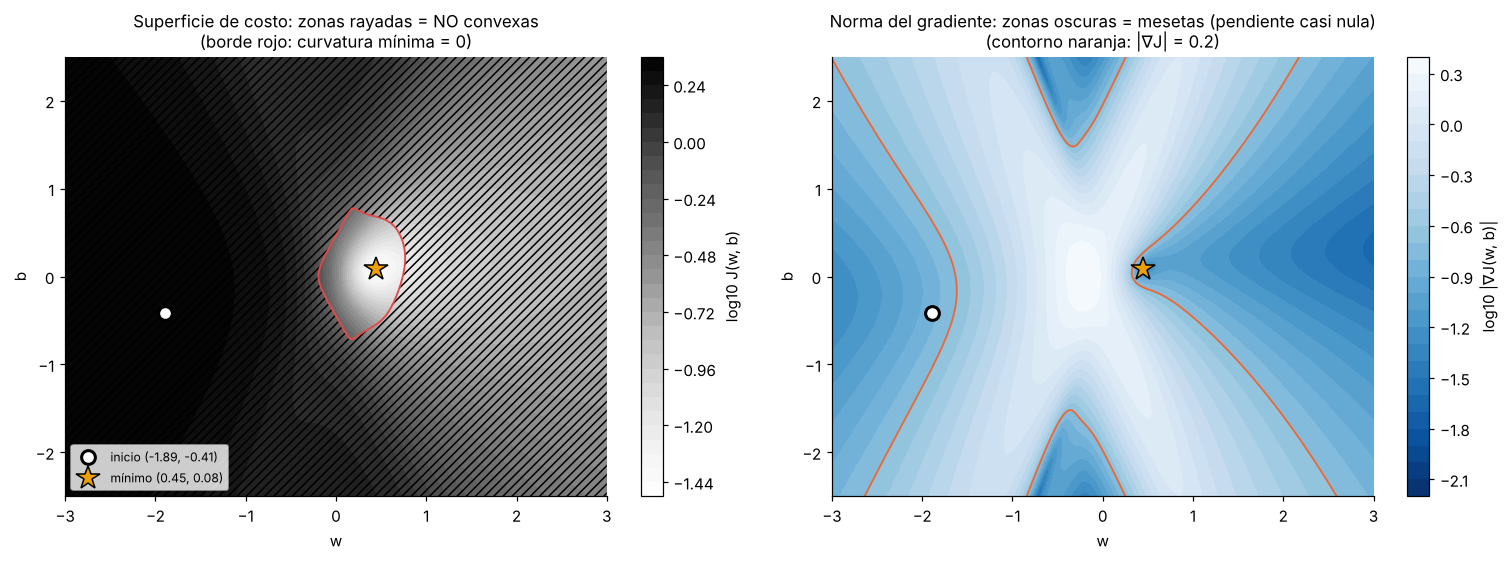

In [14]:
# 1d) Antes de la trayectoria: ¿cómo es el "terreno" J(w, b)?
# Curvatura (Hessiano) para ubicar zonas NO convexas y norma del gradiente para ubicar mesetas.
wl = np.linspace(-3, 3, 241); bl = np.linspace(-2.5, 2.5, 201)
WL, BL = np.meshgrid(wl, bl)
JL = cost_grid(WL, BL)
lam_min = np.empty_like(JL); gnorm = np.empty_like(JL)
for i in range(WL.shape[0]):
    t = np.tanh(WL[i][:, None] * x + BL[i][:, None]); s = 1 - t ** 2
    h = (2 / N) * s * (s - 2 * t * (t - y)); d = (2 / N) * (t - y) * s
    Hww, Hwb, Hbb = h @ (x * x), h @ x, h.sum(axis=1)
    tr, det = Hww + Hbb, Hww * Hbb - Hwb ** 2
    lam_min[i] = tr / 2 - np.sqrt(np.maximum((tr / 2) ** 2 - det, 0))   # autovalor mínimo del Hessiano 2x2
    gnorm[i] = np.hypot(d @ x, d.sum(axis=1))

print(f"En la ventana w∈[-3,3], b∈[-2.5,2.5]: {np.mean(lam_min < 0):.0%} del área es NO convexa (Hessiano con un autovalor < 0)")
print(f"|grad J| en el punto inicial = {np.linalg.norm(grad(W0, B0)):.3f}  vs  mediana en la ventana = {np.median(gnorm):.3f}"
      f"  vs  máximo = {gnorm.max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
cf = ax.contourf(WL, BL, np.log10(JL), levels=30, cmap="Greys")
ax.contourf(WL, BL, (lam_min < 0).astype(float), levels=[0.5, 1.5], colors="none", hatches=["////"])
ax.contour(WL, BL, lam_min, levels=[0], colors="#e34948", linewidths=1.2)
plt.colorbar(cf, ax=ax, label="log10 J(w, b)")
ax.set_title("Superficie de costo: zonas rayadas = NO convexas\n(borde rojo: curvatura mínima = 0)")
ax2 = axes[1]
im = ax2.contourf(WL, BL, np.log10(gnorm + 1e-12), levels=30, cmap="Blues_r")
plt.colorbar(im, ax=ax2, label="log10 |∇J(w, b)|")
ax2.contour(WL, BL, gnorm, levels=[0.2], colors="#eb6834", linewidths=1.2)
ax2.set_title("Norma del gradiente: zonas oscuras = mesetas (pendiente casi nula)\n(contorno naranja: |∇J| = 0.2)")
for a in axes:
    a.plot(W0, B0, "o", ms=9, mfc="white", mec="k", mew=2, label=f"inicio ({W0:.2f}, {B0:.2f})")
    a.plot(W_STAR, B_STAR, "*", ms=16, color="#eda100", mec="k", label=f"mínimo ({W_STAR:.2f}, {B_STAR:.2f})")
    a.set_xlabel("w"); a.set_ylabel("b"); a.grid(False)
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()


Me sorprendió lo poco convexa que es: el 97% de la ventana tiene curvatura negativa en alguna dirección. Lo único con forma de pozo es una isla alrededor del mínimo (borde rojo). Hay mesetas en los cuatro lados y todas vienen de la saturación de la tanh. A la izquierda está el modelo invertido y saturado (J cerca de 2.2), que es donde arranco. A la derecha la tanh se vuelve casi un escalón (J entre 0.12 y 0.14). Arriba y abajo, con |b| grande, la salida queda clavada en ±1. En el medio hay un canal con gradientes de hasta 2.5. El punto inicial tiene gradiente 0.146, por debajo de la mediana de la ventana (0.24).

Para elegir el lr del 3D no quise hacerlo a ojo. Para cada lr calculé la distancia promedio, época a época, entre las posiciones de cada par de optimizadores, y me quedé con el de mayor separación.

In [15]:
# --- ¿Qué learning rate muestra mejor la diferencia? Lo medimos en vez de elegir "a ojo" ---
# Separación = distancia promedio (a lo largo de las 101 épocas) entre las posiciones (w, b) de cada par de optimizadores.
def separacion(lr):
    P = {opt: np.c_[results[opt][lr]["w"], results[opt][lr]["b"]] for opt in OPTS}
    pares = [(OPTS[i], OPTS[j]) for i in range(3) for j in range(i + 1, 3)]
    return np.mean([np.linalg.norm(P[a] - P[b], axis=1).mean() for a, b in pares])

sep = {lr: separacion(lr) for lr in LRS}
for lr in LRS:
    print(f"lr = {lr:<6} separación media entre trayectorias = {sep[lr]:.3f}")
LR_3D = max(sep, key=sep.get)
print(f"\n-> Learning rate elegido para la visualización 3D: {LR_3D}")


lr = 0.1    separación media entre trayectorias = 1.355
lr = 0.01   separación media entre trayectorias = 1.653
lr = 0.001  separación media entre trayectorias = 0.749

-> Learning rate elegido para la visualización 3D: 0.01


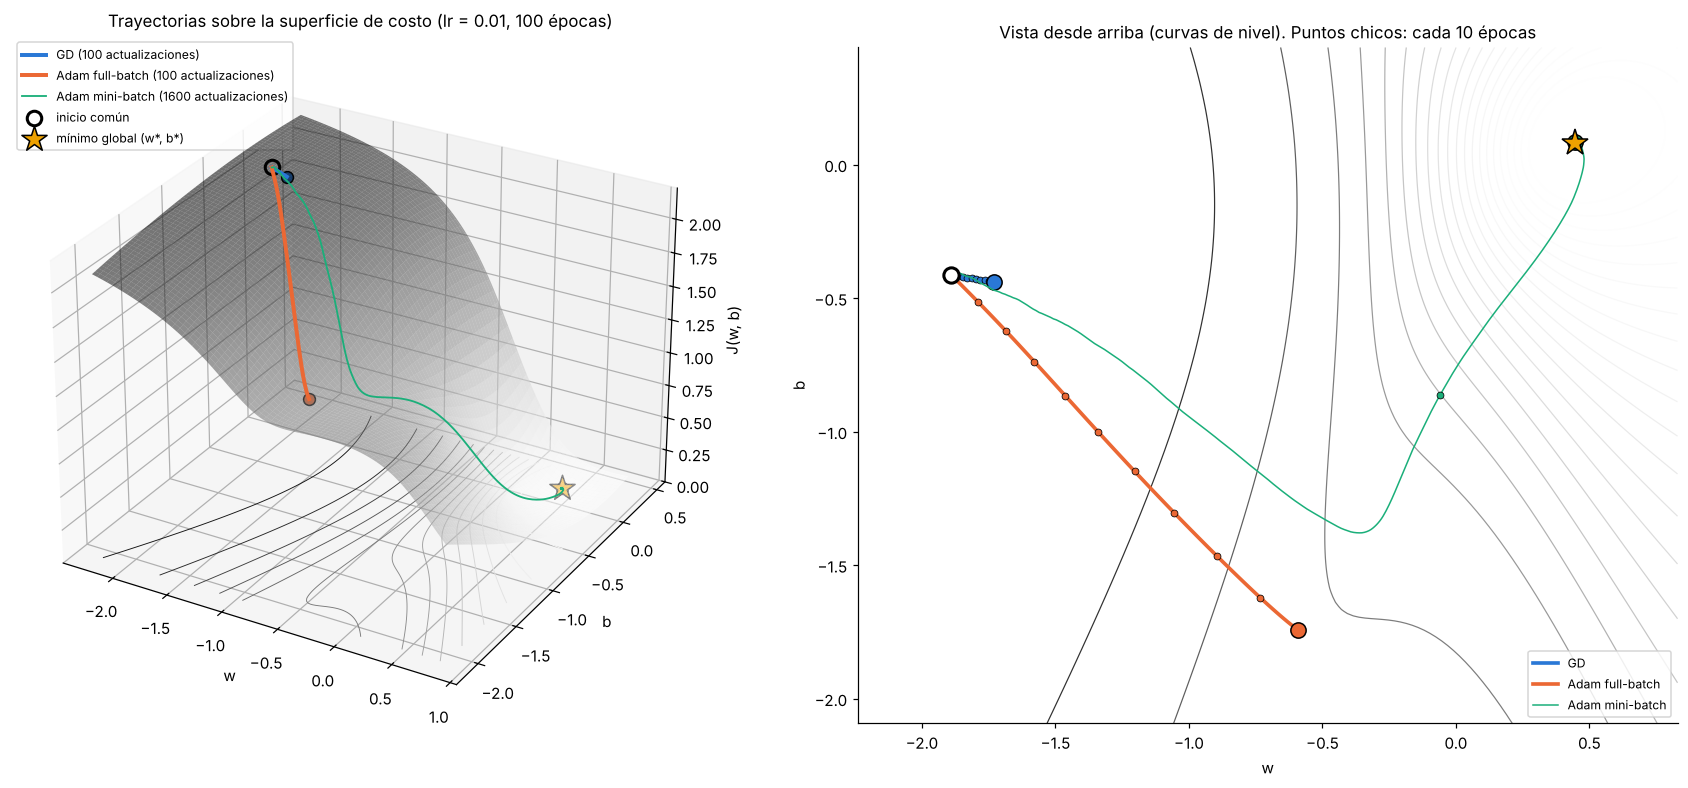

In [16]:
# --- Trayectorias de los 3 optimizadores sobre la superficie 3D de J(w, b) (mismo punto de partida) ---
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registra la proyección 3D)

def ventana(lr, pad=0.35):
    ws = np.concatenate([results[o][lr]["path_w"] for o in OPTS] + [[W_STAR]])
    bs_ = np.concatenate([results[o][lr]["path_b"] for o in OPTS] + [[B_STAR]])
    return ws.min() - pad, ws.max() + pad, bs_.min() - pad, bs_.max() + pad

w_lo, w_hi, b_lo, b_hi = ventana(LR_3D)
W3, B3 = np.meshgrid(np.linspace(w_lo, w_hi, 140), np.linspace(b_lo, b_hi, 140))
J3 = cost_grid(W3, B3)

fig = plt.figure(figsize=(16, 7))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(W3, B3, J3, cmap="Greys", alpha=0.55, linewidth=0, antialiased=True, rstride=2, cstride=2)
ax.contour(W3, B3, J3, levels=15, zdir="z", offset=0, cmap="Greys", linewidths=0.6)
lift = 0.02 * (J3.max() - J3.min())          # pequeño desplazamiento vertical para que la línea no quede tapada
for opt in OPTS:
    r = results[opt][LR_3D]
    pw, pb = r["path_w"], r["path_b"]
    pj = np.array([cost(a, b) for a, b in zip(pw, pb)])
    lw = 1.2 if opt == "Adam mini-batch" else 2.6
    ax.plot(pw, pb, pj + lift, color=COLOR_OPT[opt], lw=lw, label=f"{opt} ({r['updates']} actualizaciones)", zorder=10)
    ax.scatter(pw[-1], pb[-1], pj[-1] + lift, color=COLOR_OPT[opt], s=60, edgecolor="k", zorder=11)
ax.scatter(W0, B0, cost(W0, B0) + lift, color="white", edgecolor="k", s=90, linewidth=2, label="inicio común", zorder=12)
ax.scatter(W_STAR, B_STAR, J_STAR + lift, color="#eda100", edgecolor="k", marker="*", s=300, label="mínimo global (w*, b*)", zorder=12)
ax.set_xlabel("w"); ax.set_ylabel("b"); ax.set_zlabel("J(w, b)")
ax.set_zlim(0, J3.max()); ax.view_init(elev=28, azim=-60)
ax.set_title(f"Trayectorias sobre la superficie de costo (lr = {LR_3D}, 100 épocas)")
ax.legend(loc="upper left", fontsize=8)

ax2 = fig.add_subplot(1, 2, 2)
niveles = np.geomspace(J3.min() * 1.01, J3.max(), 25)
cs = ax2.contour(W3, B3, J3, levels=niveles, cmap="Greys", linewidths=0.8)
for opt in OPTS:
    r = results[opt][LR_3D]
    lw = 1.0 if opt == "Adam mini-batch" else 2.4
    ax2.plot(r["path_w"], r["path_b"], color=COLOR_OPT[opt], lw=lw, label=opt)
    ax2.plot(r["w"][::10], r["b"][::10], "o", color=COLOR_OPT[opt], ms=4.5, mec="k", mew=0.5)   # marca cada 10 épocas
    ax2.plot(r["w"][-1], r["b"][-1], "o", color=COLOR_OPT[opt], ms=10, mec="k")
ax2.plot(W0, B0, "o", ms=10, mfc="white", mec="k", mew=2)
ax2.plot(W_STAR, B_STAR, "*", ms=18, color="#eda100", mec="k")
ax2.set_xlabel("w"); ax2.set_ylabel("b"); ax2.set_aspect("equal", adjustable="box"); ax2.grid(False)
ax2.set_title("Vista desde arriba (curvas de nivel). Puntos chicos: cada 10 épocas")
ax2.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()


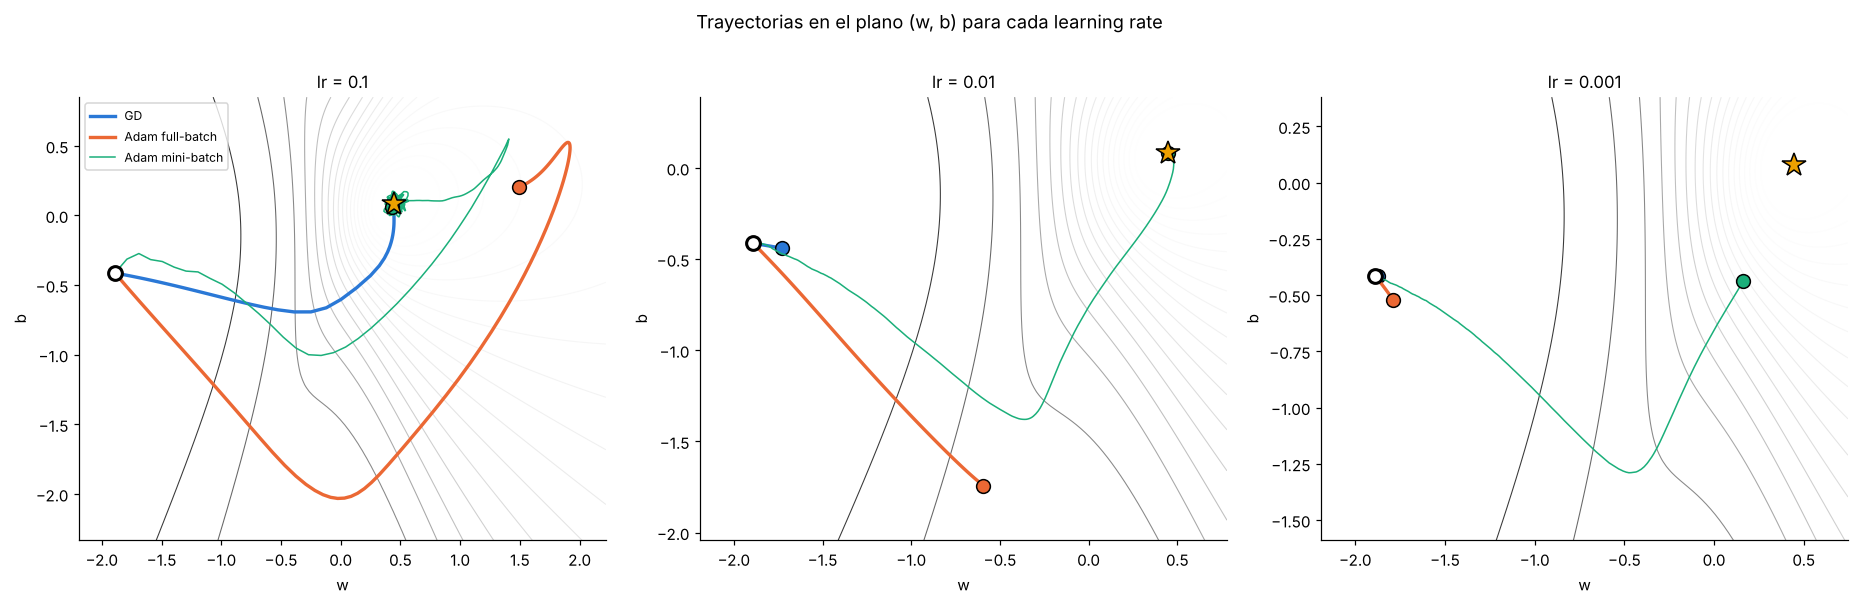

In [17]:
# --- Complemento: vista desde arriba para LOS TRES learning rates (mismo inicio) ---
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, lr in zip(axes, LRS):
    w_lo, w_hi, b_lo, b_hi = ventana(lr, pad=0.3)
    Wm, Bm = np.meshgrid(np.linspace(w_lo, w_hi, 120), np.linspace(b_lo, b_hi, 120))
    Jm = cost_grid(Wm, Bm)
    ax.contour(Wm, Bm, Jm, levels=np.geomspace(Jm.min() * 1.01, Jm.max(), 22), cmap="Greys", linewidths=0.7)
    for opt in OPTS:
        r = results[opt][lr]
        ax.plot(r["path_w"], r["path_b"], color=COLOR_OPT[opt], lw=1.0 if opt == "Adam mini-batch" else 2.2, label=opt)
        ax.plot(r["w"][-1], r["b"][-1], "o", color=COLOR_OPT[opt], ms=9, mec="k")
    ax.plot(W0, B0, "o", ms=9, mfc="white", mec="k", mew=2)
    ax.plot(W_STAR, B_STAR, "*", ms=16, color="#eda100", mec="k")
    ax.set_title(f"lr = {lr}"); ax.set_xlabel("w"); ax.set_ylabel("b"); ax.grid(False)
axes[0].legend(loc="best", fontsize=8)
fig.suptitle("Trayectorias en el plano (w, b) para cada learning rate", y=1.01)
plt.tight_layout(); plt.show()


Para entender por qué se mueven así, guardé en cada actualización el tamaño del gradiente y el tamaño del paso. La línea punteada es el paso "nominal" de Adam al comienzo (lr en cada parámetro, lr·√2 en el plano).

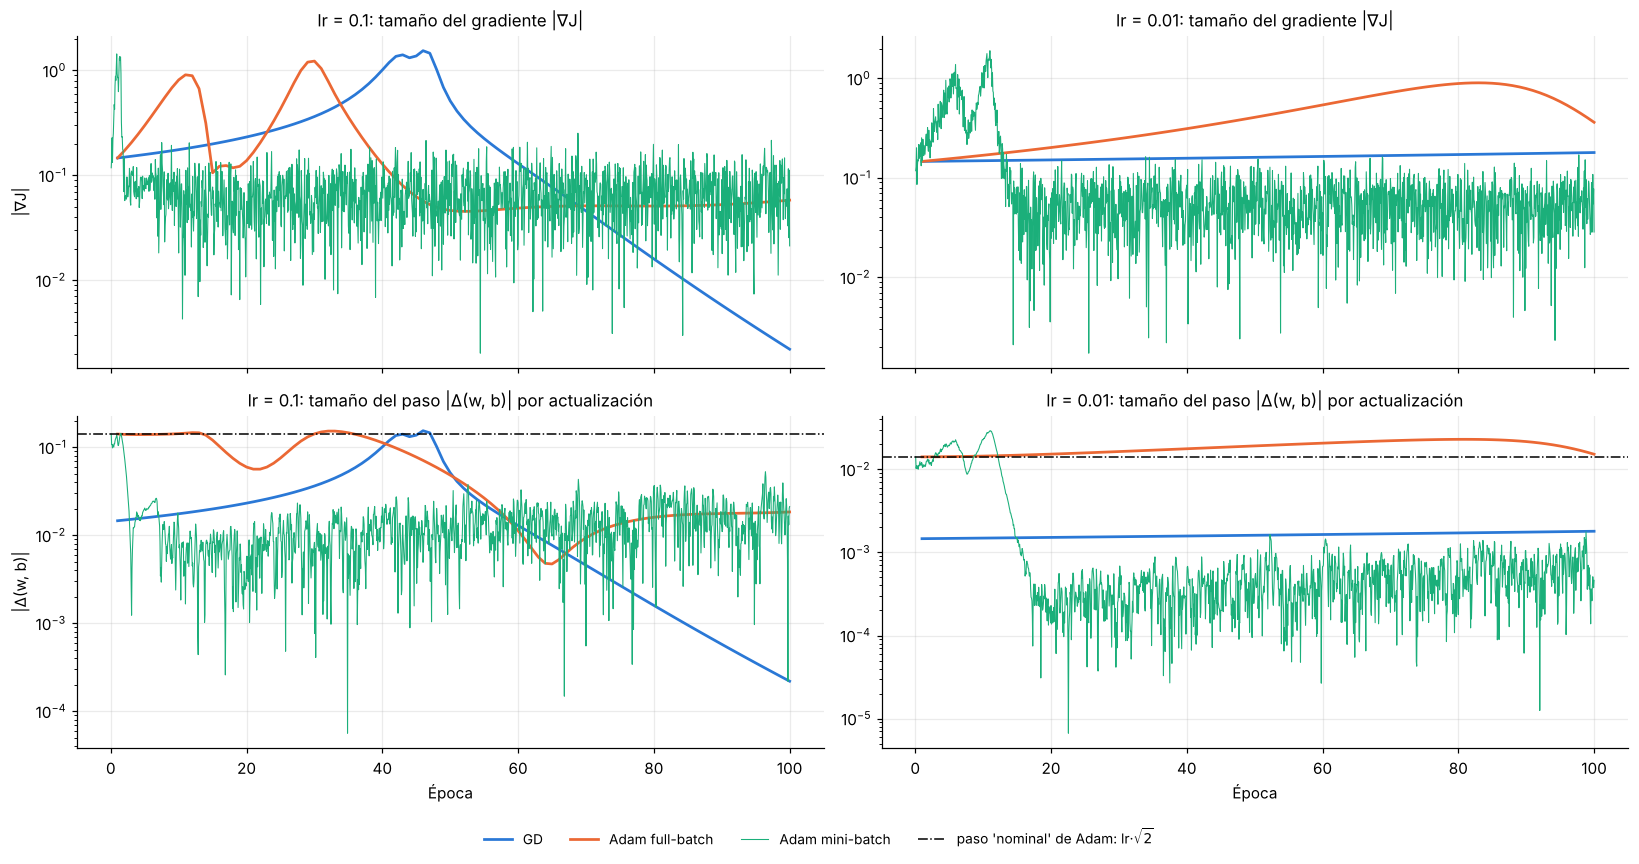

Adam full-batch, lr = 0.1
 época |   w     |  |∇J|   | sqrt(v_hat_w) | |paso|
    1  | -1.790  | 0.1464  |    0.1447     | 0.1414
   10  | -0.882  | 0.8131  |    0.4236     | 0.1430
   20  | -0.026  | 0.1381  |    0.4357     | 0.0597
   30  | +0.675  | 1.2284  |    0.5066     | 0.1422
   40  | +1.537  | 0.1282  |    0.4746     | 0.1130
   50  | +1.865  | 0.0463  |    0.4239     | 0.0483
   60  | +1.919  | 0.0487  |    0.3863     | 0.0113
   80  | +1.779  | 0.0510  |    0.3335     | 0.0160
  100  | +1.496  | 0.0580  |    0.2977     | 0.0184


In [18]:
# --- Diagnóstico: ¿por qué se mueven así? Tamaño del gradiente vs tamaño del paso que da cada optimizador ---
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharex=True)
for col, lr in enumerate([0.1, 0.01]):
    for opt in OPTS:
        r = results[opt][lr]; d = r["diag"]
        ep_k = np.arange(1, len(d) + 1) / (r["updates"] / EPOCHS)        # actualización -> época equivalente
        lw = 0.7 if opt == "Adam mini-batch" else 1.8
        axes[0, col].plot(ep_k, d[:, 0], color=COLOR_OPT[opt], lw=lw, label=opt)
        axes[1, col].plot(ep_k, d[:, 1], color=COLOR_OPT[opt], lw=lw, label=opt)
    axes[1, col].axhline(lr * np.sqrt(2), color="k", ls="-.", lw=1, label=r"paso 'nominal' de Adam: lr·$\sqrt{2}$")
    axes[0, col].set_title(f"lr = {lr}: tamaño del gradiente |∇J|"); axes[1, col].set_title(f"lr = {lr}: tamaño del paso |Δ(w, b)| por actualización")
    for a in axes[:, col]: a.set_yscale("log")
    axes[1, col].set_xlabel("Época")
axes[0, 0].set_ylabel("|∇J|"); axes[1, 0].set_ylabel("|Δ(w, b)|")
plt.tight_layout()
fig.legend(*axes[1, 0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.05), frameon=False)
plt.show()

# Evidencia numérica del "frenado" de Adam full-batch con lr = 0.1 (memoria larga de v con beta2 = 0.999)
d = results["Adam full-batch"][0.1]["diag"]; r = results["Adam full-batch"][0.1]
print("Adam full-batch, lr = 0.1")
print(" época |   w     |  |∇J|   | sqrt(v_hat_w) | |paso|")
for e in [1, 10, 20, 30, 40, 50, 60, 80, 100]:
    print(f"  {e:3d}  | {r['w'][e]:+.3f}  | {d[e-1, 0]:.4f}  |    {d[e-1, 2]:.4f}     | {d[e-1, 1]:.4f}")


Tenía una hipótesis sobre por qué full-batch con lr 0.1 se pasa y después vuelve lento (inercia por un lado, memoria larga de v por el otro). Para comprobarla, repetí esa corrida cambiando una pieza por vez.

In [19]:
# --- Ablación: ¿qué pieza de Adam causa el sobrepaso y el frenado de Adam full-batch con lr = 0.1? ---
# Misma corrida (mismo inicio, lr = 0.1, full-batch) apagando o acortando una pieza por vez.
variantes = [
    ("Adam original (β1=0.9, β2=0.999)",            dict()),
    ("sin momento (β1=0)",                          dict(beta1=0.0)),
    ("memoria de escala más corta (β2=0.99)",       dict(beta2=0.99)),
    ("memoria de escala mucho más corta (β2=0.9)",  dict(beta2=0.9)),
    ("Adam original con 300 épocas",                dict(epochs=300)),
]
filas = []
for nombre, kw in variantes:
    r = train_adam(W0, B0, 0.1, **kw)
    filas.append({"variante": nombre, "J final": r["J"][-1], "brecha vs J* (%)": 100 * (r["J"][-1] / J_STAR - 1),
                  "w máximo alcanzado": r["w"].max(), "época estable": epoca_estable(r["J"]), "épocas": len(r["J"]) - 1})
display(pd.DataFrame(filas).set_index("variante").style.format(
    {"J final": "{:.5f}", "brecha vs J* (%)": "{:.1f}", "w máximo alcanzado": "{:+.2f}",
     "época estable": lambda v: "no alcanza" if np.isnan(v) else f"{int(v)}"}))


,J final,brecha vs J* (%),w máximo alcanzado,época estable,épocas
variante,,,,,
"Adam original (β1=0.9, β2=0.999)",0.11280,228.7,+1.92,no alcanza,100
sin momento (β1=0),0.03431,0.0,+0.45,25,100
memoria de escala más corta (β2=0.99),0.11081,222.9,+1.93,no alcanza,100
memoria de escala mucho más corta (β2=0.9),0.03966,15.6,+2.25,no alcanza,100
Adam original con 300 épocas,0.03431,0.0,+1.92,149,300


Animación de lo mismo con lr = 0.01, época por época. Se puede pausar y avanzar cuadro a cuadro; sirve para ver la velocidad de cada uno, que en el gráfico estático no se nota.

In [20]:
# --- Animación (opcional en la consigna): la "carrera" de los 3 optimizadores, época a época ---
plt.rcParams["animation.embed_limit"] = 40   # MB
w_lo, w_hi, b_lo, b_hi = ventana(LR_3D)
fig, ax = plt.subplots(figsize=(7.2, 5.8))
ax.contour(W3, B3, J3, levels=np.geomspace(J3.min() * 1.01, J3.max(), 25), cmap="Greys", linewidths=0.7)
ax.plot(W_STAR, B_STAR, "*", ms=18, color="#eda100", mec="k", zorder=5)
ax.plot(W0, B0, "o", ms=9, mfc="white", mec="k", mew=2, zorder=5)
lineas, puntos = {}, {}
for opt in OPTS:
    lineas[opt], = ax.plot([], [], color=COLOR_OPT[opt], lw=1.0 if opt == "Adam mini-batch" else 2.2, label=opt)
    puntos[opt], = ax.plot([], [], "o", color=COLOR_OPT[opt], ms=10, mec="k", zorder=6)
ax.set_xlim(w_lo, w_hi); ax.set_ylim(b_lo, b_hi); ax.set_xlabel("w"); ax.set_ylabel("b"); ax.grid(False)
ax.legend(loc="lower right", fontsize=8)
titulo = ax.set_title("")
CORTO = {"GD": "GD", "Adam full-batch": "Adam FB", "Adam mini-batch": "Adam MB"}
pasos_por_epoca = {opt: results[opt][LR_3D]["updates"] // EPOCHS for opt in OPTS}

def actualizar(e):
    for opt in OPTS:
        r = results[opt][LR_3D]; k = e * pasos_por_epoca[opt]
        lineas[opt].set_data(r["path_w"][:k + 1], r["path_b"][:k + 1])
        puntos[opt].set_data([r["w"][e]], [r["b"][e]])
    titulo.set_text(f"lr = {LR_3D}  |  época {e:3d}\n" +
                    "   ".join(f"{CORTO[o]}: J = {results[o][LR_3D]['J'][e]:.3f}" for o in OPTS))
    return list(lineas.values()) + list(puntos.values()) + [titulo]

anim = animation.FuncAnimation(fig, actualizar, frames=range(0, EPOCHS + 1, 2), interval=120, blit=False)
plt.close(fig)
with plt.rc_context({"savefig.dpi": 72}):     # resolución moderada para que el notebook no pese demasiado
    display(HTML(anim.to_jshtml()))


### Análisis 1d

El lr con mayor separación fue 0.01 (1.65, contra 1.36 con 0.1 y 0.75 con 0.001), así que el 3D es con ese. Agregué igual la vista desde arriba para los tres lr, porque con 0.1 aparece algo que con 0.01 no se ve: el sobrepaso.

**GD (lr 0.01).** Se mueve en la dirección de máxima bajada, perpendicular a las curvas de nivel. Al inicio la derivada en w es 6.5 veces la de b, así que se mueve casi solo en w (el primer paso apunta unos 9° hacia abajo). Pero cada paso es 0.01 x 0.146, unos 0.0015. En 100 épocas recorre 0.16 y en el 3D casi ni se ve. No está atrapado en un mínimo, está en la meseta.

**Adam full-batch (lr 0.01).** El primer paso es exactamente (+0.01, -0.01): en la primera actualización m/√v vale el signo del gradiente, así que mueve los dos parámetros lo mismo, sin importar que la pendiente en b sea 6.5 veces menor. Por eso la trayectoria es una recta a 45° que lleva b hacia -1.74, cuando el óptimo está en +0.08. Sale de la meseta, que GD no puede, pero no va en la dirección de máximo descenso. Avanza entre 0.014 y 0.022 por época (un poco más que el lr cuando el gradiente crece, porque √v tiene memoria larga y va atrasado) y termina a mitad de la ladera (J = 1.36).

**Adam mini-batch (lr 0.01).** Empieza con la misma diagonal, pero da 16 pasos por época. Hacia la época 10 entra al canal, baja b hasta -1.38, gira (cruza w = 0 en la época 11) y desde la 14 queda en el pozo. Lo que me llamó la atención: una vez ahí, el gradiente de cada lote sigue siendo de 0.05 por el ruido, pero los signos se alternan, entonces m se promedia a casi cero mientras v mantiene la magnitud. El paso cae a 0.0005. Adam termina filtrando solo el ruido del mini-batch.

**Con lr 0.1.** GD hace una curva suave y entra al mínimo sin pasarse; como dije en 1c, para oscilar necesitaría un lr mayor a 1.76. Full-batch hace un rodeo enorme: baja b hasta -2.0, cruza el canal con la inercia acumulada (w = 0 en la época 21) y se pasa hasta w = 1.92 (época 59), ya en la meseta derecha. De ahí vuelve muy despacio. La tabla del diagnóstico muestra por qué: al cruzar el canal vio gradientes de 1.2 y √v quedó en 0.5. En la meseta el gradiente es 0.05, pero √v sigue en 0.3-0.4 porque se "acuerda" del canal, y el paso queda en 0.011-0.018, unas diez veces menos de lo normal. Mini-batch también se pasa (hasta w = 1.41), pero vuelve enseguida porque tiene 16 veces más pasos, y después orbita el mínimo con pasos de 0.015. Ese es el ruido que se ve en su curva de costo.

**Ablación.** Confirmó la hipótesis. Sin momento (β1 = 0) no se pasa (w máximo 0.45) y llega a J* en la época 25, antes que GD. Con β2 = 0.9 (memoria de unos 10 pasos) se pasa todavía más, pero vuelve rápido y termina en 0.040. Con β2 = 0.99 casi no cambia, porque una memoria de 100 pasos sigue cubriendo toda la corrida. Con 300 épocas, el Adam original también converge (estable desde la 149). O sea: el momento produce el sobrepaso y la memoria larga de v hace lenta la vuelta. No es que Adam no funcione: en 100 pasos no le alcanza para corregirse.

En resumen: GD es preciso pero depende del terreno, y en las mesetas que genera la tanh saturada se queda. Adam no depende de la escala del gradiente y por eso escapa, pero deforma la dirección (las diagonales) y carga inercia y memoria que lo pueden hacer pasarse. Mini-batch le da muchas más oportunidades de corregir, y por eso con lr 0.01 es el único que, desde este arranque difícil, llega al mínimo y se queda.

### **RECOMENDACIÓN**:

Voy a valorar mucho que sus análisis, explicaciones y conclusiones sean bastante detalladas y con coherencia en los resultados obtenidos. Donde se evidencie un análisis propio de un humano estudiante de posgrado y no solo copiar y pegar lo que te dijo ChatGPT. Llevo ya años con esto, así que me daré cuenta rapidamente cuando sea así y cuando no.

Les recomiendo revisar el notebook sobre optimizadores que se encuentra en el repo. Pueden acceder mediante el siguiente [enlace](https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/aprendizaje_profundo/blob/ap_2026/CLASE%202/Notebooks/clase2_4_optimizadores.ipynb). En ese notebook vemos cómo aplicar GD y Adam full-batch para una red con relación lineal. Les servirá mucho como guía para realizar esta pregunta. Ahí también podrán ver cómo se hace una animación de un gráfico 3D.

Además, de igual forma tienen disponible el siguiente [material adicional del repo](https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/aprendizaje_profundo/tree/ap_2026/CLASE%202/Teoria/Material%20adicional), el cual le servirá para aplicar Adam, ya no solo en su versión full-batch, sino también en mini-batch

# **PREGUNTA 2** (Temas de la clase 3)

# Caso: Predicción del gasto promedio de los usuarios usando redes neuronales

**Descarga del dataset:**  
El conjunto de datos puede descargarse en el siguiente [enlace](https://drive.google.com/file/d/1e_FRepCpHBWWGj3TYG4HY7WHALCyR4wQ/view?usp=sharing)

---

## Descripción general:

El dataset recopila información sobre las compras realizadas por distintos clientes en una tienda durante el último año.  
Cada registro representa una transacción e incluye datos tanto del cliente como del producto adquirido.

---

## El dataset contiene la siguiente información:

- **User_ID:** Código identificador único del cliente que efectuó la compra.  
- **Product_ID:** Código identificador único del producto adquirido.  
- **Age:** Rango de edad del cliente.  
- **Gender:** Género del cliente (F: Femenino, M: Masculino).  
- **Marital_Status:** Estado civil del cliente (0: Soltero, 1: Casado).  
- **City_Category:** Tipo de zona donde se encuentra la sucursal donde se realizó la compra.  
  - A: Barrio de clase alta  
  - B: Barrio de clase media  
  - C: Barrio de clase media-baja  
- **Stay_In_Current_City_Years:** Número de años que el cliente ha venido comprando en la tienda desde su primera visita.  
- **Product_Category:** Categoría del producto comprado.  
- **Product_Subcategory_1:** Subcategoría principal del producto.  
- **Product_Subcategory_2:** Subcategoría secundaria del producto.  
- **Purchase:** Monto pagado por el producto en esa transacción.

---

## Objetivo del caso de estudio:

Desarrollar un **modelo predictivo** capaz de estimar el **gasto promedio** que realizará un cliente, a partir de su información demográfica, sus patrones de compra, gustos y comportamiento. Tener en cuenta que se busca que el modelo prediga el gasto promedio por cliente, no el gasto en cada nueva transacción individual. Y la idea sería que una vez que el modelo ya esté listo y entrenado, se use para estimar apartir de datos de clientes relativamente nuevos, que solo llevan unas pocas visitas y compras en la tienda. Por ende, el modelo debería poder hacer una inferencia de los datos sin depender de la cantidad de compras de cada cliente.


### 2a) EDA y preparación del dataset (2 puntos)
Realizar el análisis exploratorio del dataset (EDA) con las herramientas vistas en materias anteriores.
- Analizar qué columnas sirven para lograr el objetivo y cuáles no (drop) en base al contexto del negocio y a lo entendido del caso de estudio (feature engineering).
- Analizar con qué columnas vale la pena hacer un tratamiento de valores nulos o si simplemente se debe dropear toda la columna porque ya no tiene salvación.
- Analizar a qué variables se les debe hacer label encoding, a cuáles one-hot encoding, ordinal encoding o mapping encoding. Explicar detalladamente los criterios utilizados para tomar esas decisiones.
- Transformar, agrupar, combinar y operar la data de tal manera que sea útil para extraer patrones de gastos y tendencias de gustos de cada cliente. **Tener mucho cuidado con el data leakage, ocurre mucho cuando se usan proporciones como nuevas columnas**.



Redactar las conclusiones preliminares que puedan notar de cada feature y justificar el porqué de cada encoding, limpieza o transformación aplicada. Cada justificación se debe redactar a detalle y sustentar con gráficas y/o tablas.


### 2b) Modelo Multilayer Perceptron (MLP) (2.5 puntos)
Entrenar un modelo de deep learning usando PyTorch que consuma el dataframe ya pre-procesado en el paso anterior.

Características para el diseño de la red:
- El modelo debe tener un mínimo de 3 capas ocultas.
- El modelo debe tener un mínimo de 32 neuronas por cada capa oculta.
- Cada capa oculta debe tener su respectiva función de activación.
- La elección de la función de activación de las capas ocultas es libre, pero se debe justificar por qué se está eligiendo esa, ya sea mediante conceptos teóricos o con resultados de pruebas empíricas.
- Analizar y justificar cuál es la mejor función de costo, algoritmo de optimización y learning rate para este modelo.
- Analizar cuál sería el mejor número de épocas para entrenar el modelo.
- Opcional: Incluir técnicas de regularización como dropout en las capas ocultas.

### 2c) Evaluación del Modelo (1 punto)
- Graficar las evoluciones por época de la función de costo y del $R^2$, tanto para el set de train como el de validation.
- Gráfica scatter de Real VS Predicho en el set de validation.
- Explicar el proceso estratégico de iteracion utilizado para conseguir los mejores resultados y justificar los resultados obtenidos.
- Un resultado aceptable sería un $R^2$ de por lo menos 0.70 para el set de validation.

### 2d) Conclusiones finales (0.5 puntos)
Redactar de manera detallada las conclusiones finales y si se cumplió con el objetivo o no.